# Dengue Early-Warning for Sri Lankan Districts
### Predicting high-transmission dengue weeks two weeks ahead with an Explainable Boosting Machine (EBM), explained with its glass-box terms, SHAP and LIME

**Module:** Applied Machine Learning – final assignment

---
## 1. Problem statement

Dengue is Sri Lanka's biggest vector-borne disease. In this dataset, 174,687 cases were reported in 2017, the worst epidemic year, and 70,918 in 2023.
The Epidemiology Unit publishes **weekly case counts for the 26 RDHS areas** (25 districts plus Kalmunai).
Regional MOH offices and Public Health Inspectors respond to rising cases with vector-control work (fogging, larval source reduction and school/community clean-up drives).
These campaigns need **lead time**, because staff, insecticide and community mobilisation have to be scheduled in advance.

**ML task (binary classification):** at the end of report week *t*, using only information available that week, predict
whether a district's dengue cases in **week *t + 2*** will be **above that district's high-transmission threshold**.
The threshold is the district's 75th percentile of weekly cases over 2012–2021.

* Positive class (`high_risk = 1`): a week of unusually high transmission for that district.
* Two-week horizon: one week covers the reporting delay and one week covers mobilisation.

Each district has its own threshold, so Colombo (where 150 cases a week is normal) and Mullaitivu (where 5 a week is normal) are judged on their own scale.

## 2. Dataset: real Sri Lankan data

| | |
|---|---|
| **Source** | Epidemiology Unit, Ministry of Health Sri Lanka – *Weekly Epidemiological Report* (district dengue notifications) |
| **How it was collected** | The Epidemiology Unit publishes a *Weekly Epidemiological Report* (PDF) at epid.gov.lk with notified dengue cases per RDHS area. The `denguedatahub` package downloads these PDFs and extracts the tables into a tidy dataset |
| **Access** | Tidy version in the `denguedatahub` R package by Dr. Thiyanga S. Talagala, University of Sri Jayewardenepura (GitHub `thiyangt/denguedatahub`, object `srilanka_weekly_data`), exported to CSV |
| **Coverage** | 26 RDHS areas × weekly, 23 Dec 2006 – 17 May 2026 (26,311 rows) |
| **Columns** | `year`, `week`, `start.date`, `end.date`, `district`, `cases` |
| **Licence** | GPL-3 (denguedatahub); the underlying reports are public government publications |

This is a new problem for this module. It doesn't reuse the car or house price datasets that are common in other projects.

**Ethical data use.** The data are **aggregate weekly counts per health area**, published by the Ministry of Health for public surveillance. They contain no names, addresses, ages or any other individual-level or personal data, and no single patient can be identified from a district's weekly count. No consent issue arises, and the dataset is shared openly under its licence.

**Features and target (summary).** Raw inputs: district, week and weekly case count. From these, 19 engineered features (§6.4) describe the recent level, momentum, season and national situation. The target `high_risk` is 1 when cases in week *t + 2* exceed the district's 75th-percentile threshold. After cleaning there are 26,260 district-weeks: 21,528 for development (2007–2023) and 3,146 for testing (2024–2026).

## 3. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, balanced_accuracy_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from interpret.glassbox import ExplainableBoostingClassifier   # the new algorithm
import interpret, optuna, shap, lime, lime.lime_tabular

from src.features import (load_raw, clean, fit_reference, build_features, split, time_series_folds,
                          FEATURES, FEATURE_DESCRIPTIONS, HORIZON, REFERENCE_YEARS)
from src.models import PersistenceBaseline

SEED = 42
np.random.seed(SEED)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

print("numpy", np.__version__, "| pandas", pd.__version__, "| interpret (EBM)", interpret.__version__,
      "| shap", shap.__version__, "| optuna", optuna.__version__)

numpy 2.5.3 | pandas 3.0.5 | interpret (EBM) 0.7.8 | shap 0.54.1 | optuna 5.0.0


## 4. Load and inspect the raw data

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (26311, 7)


,year,week,start.date,end.date,district,cases,date
0,2006.0,52.0,12/23/2006,12/29/2006,Colombo,71.0,2006-12-23
1,2006.0,52.0,12/23/2006,12/29/2006,Gampaha,12.0,2006-12-23
2,2006.0,52.0,12/23/2006,12/29/2006,Kalutara,12.0,2006-12-23
3,2006.0,52.0,12/23/2006,12/29/2006,Kandy,20.0,2006-12-23
4,2006.0,52.0,12/23/2006,12/29/2006,Matale,4.0,2006-12-23


<class 'pandas.DataFrame'>
RangeIndex: 26311 entries, 0 to 26310
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year        26311 non-null  float64       
 1   week        26311 non-null  float64       
 2   start.date  26311 non-null  str           
 3   end.date    26311 non-null  str           
 4   district    26311 non-null  str           
 5   cases       26311 non-null  float64       
 6   date        26311 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(3), str(3)
memory usage: 2.1 MB


In [3]:
print("Missing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicate (year, week, district) rows:", raw.duplicated(["year", "week", "district"]).sum())
print("Date range:", raw["date"].min().date(), "->", raw["date"].max().date())
print("Districts:", raw["district"].nunique())
display(raw["cases"].describe().to_frame().T)
cnt = raw.groupby("district").size()
print("Rows per district (min/max):", cnt.min(), cnt.max(), "| short district:", cnt.idxmin())

Missing values per column:
 year          0
week          0
start.date    0
end.date      0
district      0
cases         0
date          0

Duplicate (year, week, district) rows: 0
Date range: 2006-12-23 -> 2026-05-11
Districts: 26


,count,mean,std,min,25%,50%,75%,max
cases,26311.0,31.681008,79.412352,0.0,2.0,9.0,29.0,2631.0


Rows per district (min/max): 1011 1012 | short district: Puttalam


In [4]:
# gaps between consecutive weeks in each district
gaps = raw.sort_values("date").groupby("district")["date"].diff().dt.days.value_counts().sort_index()
print("Days between consecutive reports:\n", gaps.to_string())

Days between consecutive reports:
 date
6.0        26
7.0     26206
8.0        26
9.0        26
14.0        1


**First observations**
* No `NaN`s and no duplicates. (The EDA below shows that the absence of `NaN`s is misleading: one district-year is recorded as zeros.) One district-week is completely missing (Puttalam, a 14-day gap). Report weeks are normally 7 days, with an occasional 6–9 day week at year boundaries.
* `cases` is a count that is **very right-skewed**: the median is 9, but the maximum is 2,631 (Colombo during the 2017 epidemic).
* The single 2006 week is a stub. The modelling period starts in 2007.

## 5. Exploratory data analysis

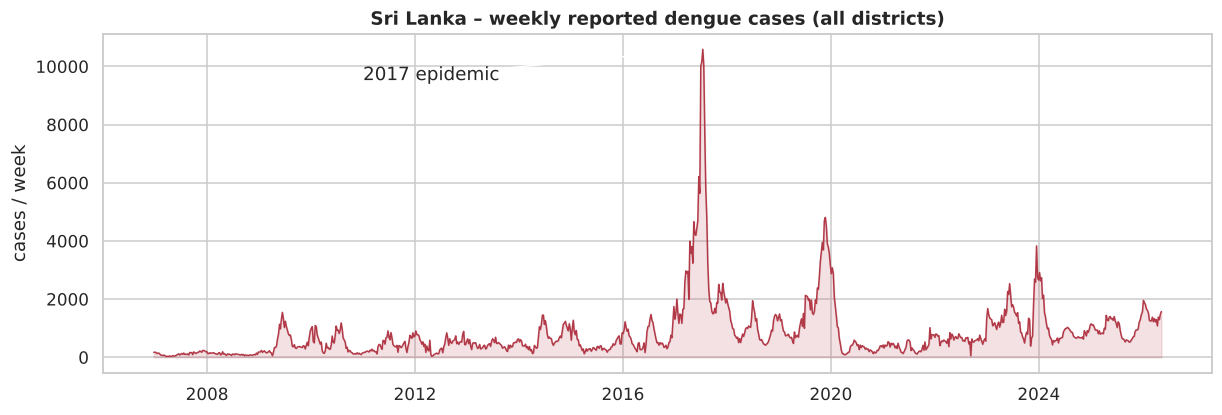

In [5]:
nat = raw.groupby("date")["cases"].sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(nat.index, nat.values, lw=1, color="#b23a48")
ax.fill_between(nat.index, nat.values, alpha=.15, color="#b23a48")
ax.set_title("Sri Lanka – weekly reported dengue cases (all districts)")
ax.set_ylabel("cases / week")
ax.annotate("2017 epidemic", xy=(pd.Timestamp("2017-07-01"), nat.max()), xytext=(pd.Timestamp("2011-01-01"), nat.max() * .9),
            arrowprops=dict(arrowstyle="->"))
savefig("eda_national_weekly"); plt.show()

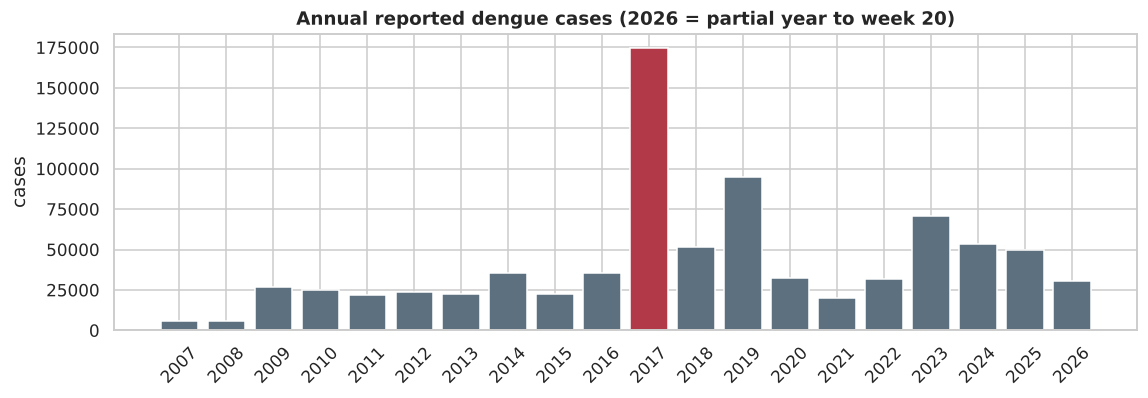

In [6]:
annual = raw[raw["year"] >= 2007].groupby("year")["cases"].sum()
fig, ax = plt.subplots(figsize=(12, 3.5))
bars = ax.bar(annual.index.astype(int).astype(str), annual.values, color=["#b23a48" if y == 2017 else "#5c7080" for y in annual.index])
ax.set_title("Annual reported dengue cases (2026 = partial year to week 20)"); ax.set_ylabel("cases")
plt.xticks(rotation=45); savefig("eda_annual"); plt.show()

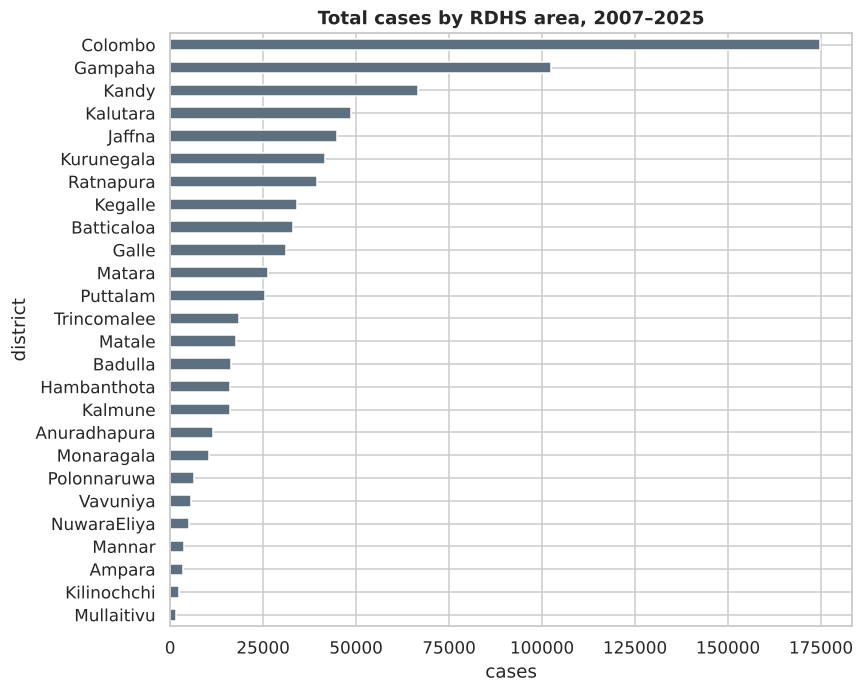

Colombo + Gampaha + Kalutara (Western Province) share: 40.5%


In [7]:
dist_tot = raw[raw["year"].between(2007, 2025)].groupby("district")["cases"].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
dist_tot.plot.barh(ax=ax, color="#5c7080")
ax.set_title("Total cases by RDHS area, 2007–2025"); ax.set_xlabel("cases")
savefig("eda_district_totals"); plt.show()
print(f"Colombo + Gampaha + Kalutara (Western Province) share: {dist_tot[['Colombo','Gampaha','Kalutara']].sum() / dist_tot.sum():.1%}")

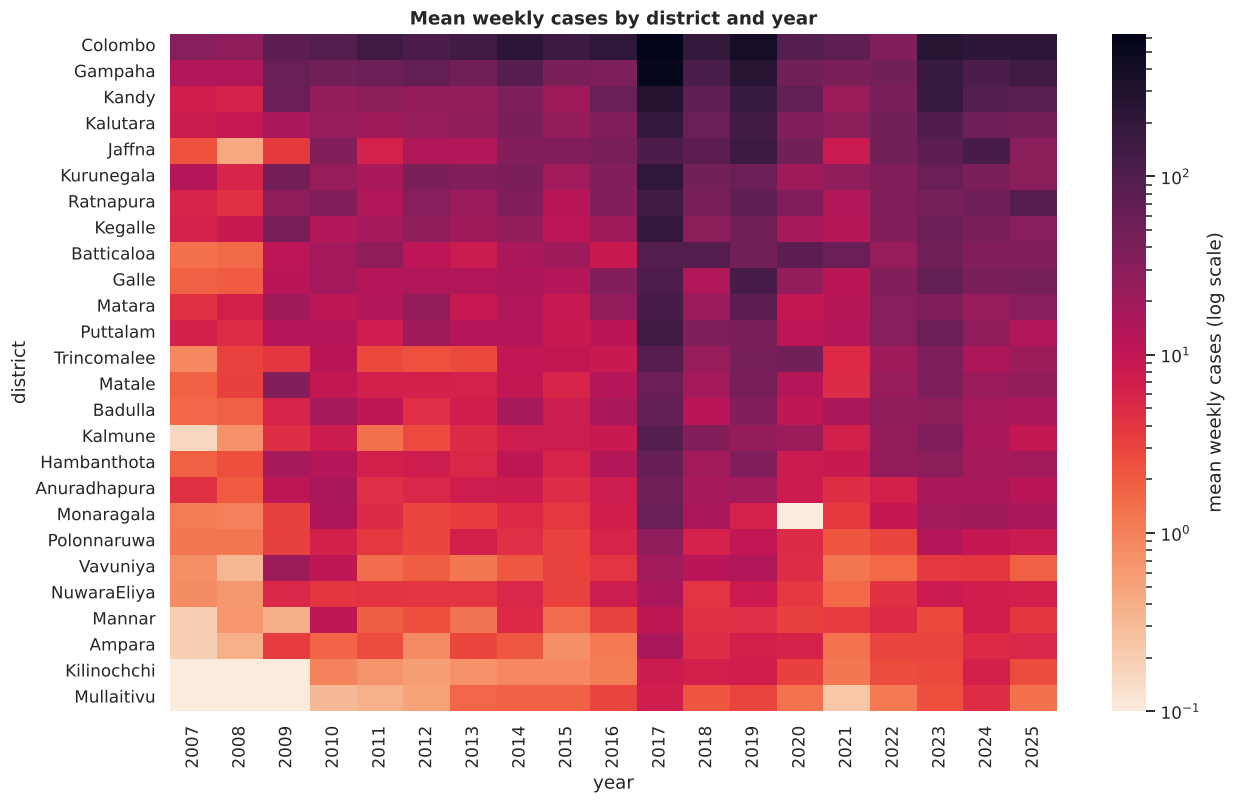

In [8]:
pivot = raw[raw["year"].between(2007, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="mean")
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(pivot + 0.1, norm=mcolors.LogNorm(), cmap="rocket_r", ax=ax, cbar_kws={"label": "mean weekly cases (log scale)"})
ax.set_xticklabels([int(float(t.get_text())) for t in ax.get_xticklabels()])
ax.set_title("Mean weekly cases by district and year")
savefig("eda_heatmap_district_year"); plt.show()

In [9]:
# Data-quality check suggested by the heatmap: district-years with (almost) no reported cases
yr_tot = raw[raw["year"].between(2009, 2025)].pivot_table(index="district", columns="year", values="cases", aggfunc="sum")
zero_years = yr_tot.stack()[lambda s: s == 0]
print("District-years with ZERO reported cases:\n", zero_years.to_string())
display(yr_tot.loc[["Monaragala"], [2018.0, 2019.0, 2020.0, 2021.0, 2022.0]])

District-years with ZERO reported cases:
 district     year  
Kilinochchi  2009.0    0.0
Monaragala   2020.0    0.0
Mullaitivu   2009.0    0.0


year,2018.0,2019.0,2020.0,2021.0,2022.0
district,,,,,
Monaragala,854.0,330.0,0.0,192.0,457.0


**Data-quality problem found.** **Monaragala reports 0 cases in every one of the 52 weeks of 2020**, compared with 330 in 2019 and 192 in 2021.
Dengue is endemic there and every neighbouring district reported cases that year, so this is a **reporting failure, with missing data recorded as zeros**.
It isn't a real absence of dengue. If left in, the model would learn that Monaragala can drop from normal levels to zero.
Handling (section 6.1): the year is set to missing, and the rows whose 52-week look-back or target week touches it are **excluded** from training and evaluation.

The near-zero counts for Kilinochchi and Mullaitivu in 2007–09 are different. Low numbers there are plausible (the end of the conflict period and small populations), and the neighbouring years are also low, so they're kept.

**Levels differ by two orders of magnitude between districts, and the whole country moves together in epidemic years** (2017, 2019, 2023).
A single threshold for all districts would make no sense. This is why the target and the features are defined **relative to each district's own normal level**.

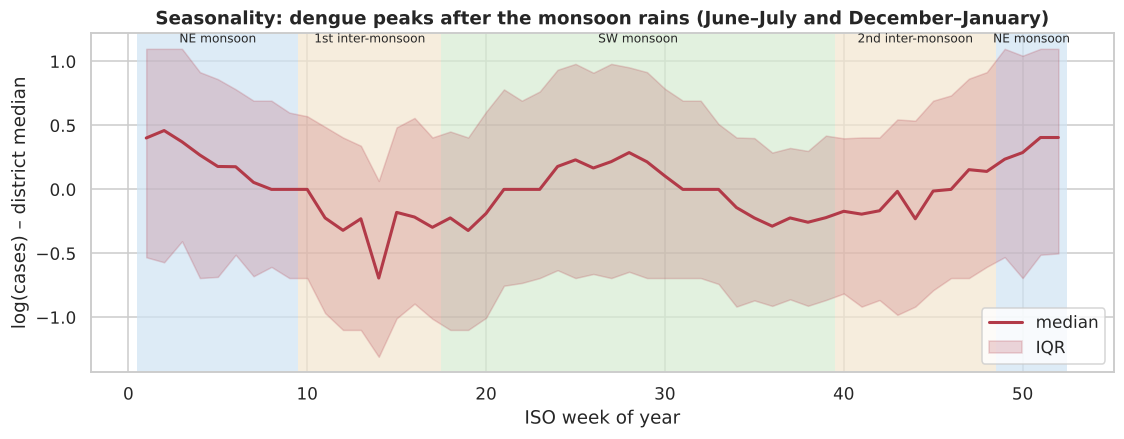

In [10]:
df = clean(raw)
df["woy"] = df["date"].dt.isocalendar().week.astype(int).clip(upper=52)
df["rel"] = np.log1p(df["cases"]) - np.log1p(df.groupby("district")["cases"].transform("median"))
season = df[df["date"].dt.year.between(2007, 2025)].groupby("woy")["rel"].agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
season.columns = ["median", "q25", "q75"]
fig, ax = plt.subplots(figsize=(12, 4))
for (a, b, lab, c) in [(1, 9, "NE monsoon", "#cfe3f3"), (10, 17, "1st inter-monsoon", "#f3e6cf"), (18, 39, "SW monsoon", "#d6ecd2"), (40, 48, "2nd inter-monsoon", "#f3e6cf"), (49, 52, "NE monsoon", "#cfe3f3")]:
    ax.axvspan(a - .5, b + .5, color=c, alpha=.7, lw=0); ax.text((a + b) / 2, season["q75"].max() + .05, lab, ha="center", fontsize=8)
ax.plot(season.index, season["median"], color="#b23a48", lw=2, label="median")
ax.fill_between(season.index, season["q25"], season["q75"], color="#b23a48", alpha=.2, label="IQR")
ax.set_xlabel("ISO week of year"); ax.set_ylabel("log(cases) – district median")
ax.set_title("Seasonality: dengue peaks after the monsoon rains (June–July and December–January)"); ax.legend(loc="lower right")
savefig("eda_seasonality"); plt.show()

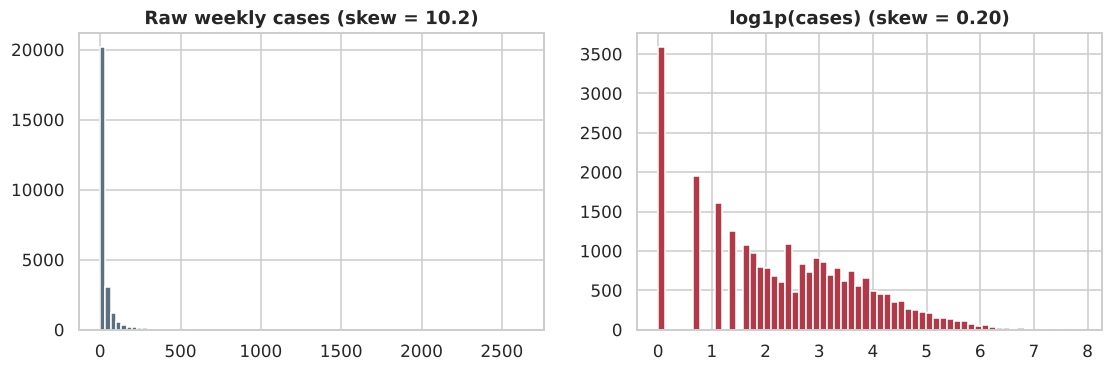

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df["cases"], bins=80, color="#5c7080"); axes[0].set_title(f"Raw weekly cases (skew = {df['cases'].skew():.1f})")
axes[1].hist(np.log1p(df["cases"]), bins=60, color="#b23a48"); axes[1].set_title(f"log1p(cases) (skew = {np.log1p(df['cases']).skew():.2f})")
savefig("eda_distribution"); plt.show()

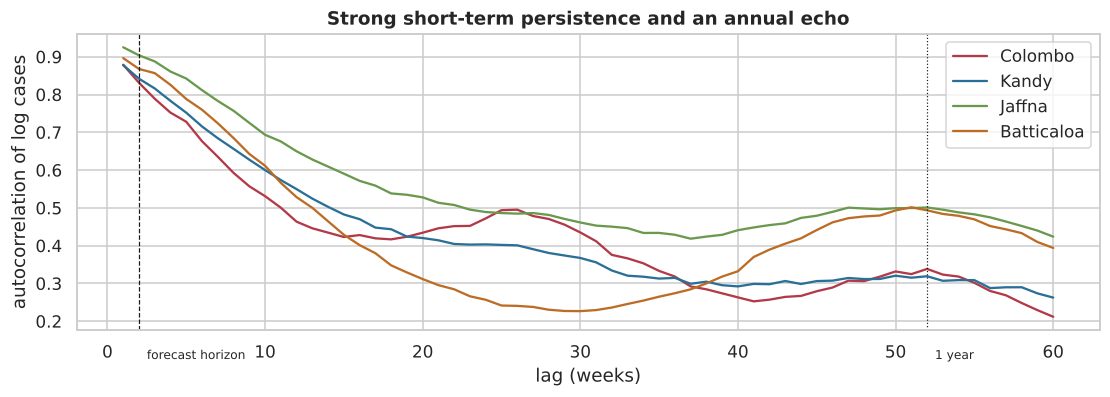

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for d, c in [("Colombo", "#b23a48"), ("Kandy", "#2a6f97"), ("Jaffna", "#6a994e"), ("Batticaloa", "#bc6c25")]:
    s = np.log1p(df.loc[df["district"] == d, "cases"].reset_index(drop=True))
    ax.plot(range(1, 61), [s.autocorr(k) for k in range(1, 61)], label=d, color=c)
ax.axvline(HORIZON, ls="--", c="k", lw=.8); ax.text(HORIZON + .5, .1, "forecast horizon", fontsize=8)
ax.axvline(52, ls=":", c="k", lw=.8); ax.text(52.5, .1, "1 year", fontsize=8)
ax.set_xlabel("lag (weeks)"); ax.set_ylabel("autocorrelation of log cases"); ax.set_title("Strong short-term persistence and an annual echo")
ax.legend(); savefig("eda_autocorrelation"); plt.show()

**EDA takeaways that shape the modelling**
1. **Skewed counts.** A `log1p` transform makes the distribution near-symmetric (skew 3+ → ~0). All count features are expressed on the log scale.
2. **Strong autocorrelation.** The lag-2 autocorrelation is above 0.8, so recent weeks are the most informative. Recent lags, moving averages and growth rates are engineered as features. This also means a **persistence baseline** ("next is like now") will be hard to beat, so we report it.
3. **Monsoon seasonality and an annual echo.** Week-of-year sine/cosine terms, a seasonal norm and "same week last year" are added as features.
4. **Nationwide waves.** National growth and the share of districts above threshold are added as features.
5. **Structural change.** Levels after 2017 are higher than in 2007–2016, so a random split would leak the future. A **chronological split** with purging is used.

## 6. Preprocessing
### 6.1 Completing the time grid and imputing missing values

In [13]:
print("District-weeks after building the full grid:", len(df))
print("Imputed values (missing week + implausible values):", int(df["was_imputed"].sum()))
imp = df[df["was_imputed"] & ~df["implausible"]]
for _, r in imp.iterrows():
    ctx = df[(df["district"] == r["district"]) & (df["date"].between(r["date"] - pd.Timedelta(weeks=2), r["date"] + pd.Timedelta(weeks=2)))]
    display(ctx[["district", "date", "cases", "was_imputed"]])

District-weeks after building the full grid: 26260
Imputed values (missing week + implausible values): 23


,district,date,cases,was_imputed
23214,Puttalam,2026-01-26,26.0,False
23215,Puttalam,2026-02-02,24.0,False
23216,Puttalam,2026-02-09,25.0,True
23217,Puttalam,2026-02-16,26.0,False
23218,Puttalam,2026-02-23,30.0,False


In [14]:
print("Weeks flagged unreliable (zeros recorded for a missing year):", int(df["unreliable"].sum()),
      "->", df.loc[df["unreliable"], "district"].unique(), df.loc[df["unreliable"], "date"].dt.year.unique())

Weeks flagged unreliable (zeros recorded for a missing year): 52 -> <ArrowStringArray>
['Monaragala']
Length: 1, dtype: str [2020]


In [15]:
# Isolated implausible weeks: < 10% of BOTH neighbouring weeks (or > 10x both), neighbours >= 30 cases
raw_lookup = raw.set_index(["district", "date"])["cases"]
imp_tbl = df[df["implausible"]][["district", "date"]].copy()
g_raw = raw.sort_values("date").groupby("district")
imp_tbl["reported"] = [raw_lookup.get((d, t)) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["prev week"] = [raw_lookup.get((d, t - pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["next week"] = [raw_lookup.get((d, t + pd.Timedelta(weeks=1))) for d, t in zip(imp_tbl["district"], imp_tbl["date"])]
imp_tbl["imputed"] = df.loc[df["implausible"], "cases"].values
print(f"Implausible isolated values: {len(imp_tbl)}")
display(imp_tbl.sort_values("date").reset_index(drop=True))
wk = raw[raw["date"] == "2026-03-30"].set_index("district")["cases"]
print("Week of 30 Mar 2026 – national total is normal (", int(wk.sum()), ") but counts are shuffled between districts:")
print(wk[["Colombo", "Gampaha", "Kalutara", "Kilinochchi", "Mannar", "Matale", "NuwaraEliya"]].to_string())

Implausible isolated values: 22


,district,date,reported,prev week,next week,imputed
0,Vavuniya,2010-01-23,2.0,55.0,30.0,42.0
1,Batticaloa,2011-10-29,3.0,58.0,40.0,49.0
2,Colombo,2012-06-09,0.0,70.0,72.0,71.0
3,Colombo,2012-07-14,0.0,99.0,206.0,152.0
4,Colombo,2012-11-03,0.0,45.0,36.0,40.0
5,Puttalam,2013-02-02,0.0,45.0,33.0,39.0
6,Badulla,2015-01-03,2.0,41.0,38.0,40.0
7,Kandy,2016-06-04,1.0,55.0,92.0,74.0
8,Galle,2016-12-10,7.0,91.0,79.0,85.0
9,Vavuniya,2020-01-04,0.0,37.0,36.0,36.0


Week of 30 Mar 2026 – national total is normal ( 1217 ) but counts are shuffled between districts:
district
Colombo          9.0
Gampaha         10.0
Kalutara        10.0
Kilinochchi    117.0
Mannar          47.0
Matale         256.0
NuwaraEliya    113.0


**Three kinds of data problem, three treatments**
* **Isolated implausible weeks (22 values):** 15 are single weeks reported as 0–7 cases between two normal weeks (for example Colombo 70 → 0 → 72), which are missed reports recorded as zero.
  The other 7 all come from the **week of 30 March 2026**. That week's national total is normal, but the counts are **misaligned between districts**: Colombo, Gampaha and Kalutara show about 10 cases, while Kilinochchi, Mannar, Matale and Nuwara Eliya show 10–30 times their normal level.
  These values are set to missing and interpolated. The rule is conservative: both neighbouring weeks must be at least 30, so genuinely small counts in low-burden districts are never touched.
* **Isolated missing week (Puttalam):** filled by **linear interpolation within the district**. Weekly counts change smoothly, so this is better than a global mean or median (that would ignore the local trend) or dropping the row (that would break the lag features for the following weeks).
* **A whole missing year (Monaragala 2020, recorded as zeros):** a year of interpolated values would be invented data, so these weeks are set to missing and interpolated only to keep the time series continuous for the *other* rows' national features.
  Every district-week whose features or target depend on them (106 rows) is **excluded** from training, CV and testing, and from the threshold and seasonal reference.

### 6.2 Outliers
Very high counts (for example the 2017 epidemic) are **real epidemics, not errors**, and they are exactly what the model must recognise. They are **kept**. Their influence is controlled by
(i) the log transform, (ii) features expressed relative to each district's threshold, and (iii) tree-based models, which split on order and are robust to extreme values.

In [16]:
lg = np.log1p(df["cases"])
q1, q3 = lg.groupby(df["district"]).transform(lambda s: s.quantile(.25)), lg.groupby(df["district"]).transform(lambda s: s.quantile(.75))
out_mask = lg > q3 + 1.5 * (q3 - q1)
print(f"Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: {out_mask.sum()} ({out_mask.mean():.1%})")
print("Share of them in 2017:", f"{(df.loc[out_mask, 'date'].dt.year == 2017).mean():.0%}")

Weeks flagged as upper outliers by the 1.5×IQR rule on log scale: 99 (0.4%)
Share of them in 2017: 73%


### 6.3 Target definition: district high-transmission thresholds
The threshold for each district is its **75th percentile of weekly cases over 2012–2021**. This is computed **inside the training period only**, so no test information leaks into the target definition. The same window gives each district's typical seasonal profile.

In [17]:
ref = fit_reference(df)
thr_tbl = pd.Series(ref["threshold"]).sort_values(ascending=False).rename("threshold (cases/week)")
display(thr_tbl.to_frame().T.round(0))

,Colombo,Gampaha,Kandy,Jaffna,Kalutara,Kurunegala,Ratnapura,Batticaloa,Kegalle,Matara,...,Matale,Anuradhapura,Monaragala,Polonnaruwa,Vavuniya,NuwaraEliya,Ampara,Mannar,Kilinochchi,Mullaitivu
threshold (cases/week),291.0,115.0,73.0,64.0,64.0,59.0,49.0,48.0,37.0,35.0,...,18.0,15.0,11.0,9.0,8.0,7.0,5.0,4.0,3.0,3.0


### 6.4 Feature engineering
All features use only data **up to week *t***. Counts are put on a log scale and **divided by the district threshold**, which turns them into log ratios, so the features have the same meaning in every district and in every era.

In [18]:
feat = build_features(df.drop(columns=["woy", "rel"]), ref)
print("Rows excluded because their window touches unreliable data:", int(feat["unreliable_window"].sum()))
display(pd.DataFrame({"feature": FEATURES, "description": [FEATURE_DESCRIPTIONS[f] for f in FEATURES]}))
display(feat[["district", "date", "cases", "threshold"] + FEATURES[:6] + ["target_cases", "high_risk"]].dropna().sample(5, random_state=SEED))

Rows excluded because their window touches unreliable data: 106


,feature,description
0,rel_now,This week's cases vs district threshold (log r...
1,rel_lag1,Cases 1 week ago vs threshold (log ratio)
2,rel_lag2,Cases 2 weeks ago vs threshold (log ratio)
3,rel_lag3,Cases 3 weeks ago vs threshold (log ratio)
4,rel_ma4,4-week average vs threshold (log ratio)
5,rel_ma8,8-week average vs threshold (log ratio)
6,rel_ma12,12-week average vs threshold (log ratio)
7,rel_ma52,52-week average vs threshold (log ratio)
8,growth_1w,Week-on-week growth (log)
9,growth_4w,Growth over 4 weeks (log)


,district,date,cases,threshold,rel_now,rel_lag1,rel_lag2,rel_lag3,rel_ma4,rel_ma8,target_cases,high_risk
23506,Ratnapura,2012-04-21,14.0,49.0,-1.203973,0.019803,-1.609438,-1.021651,-0.755023,-0.693147,17.0,0.0
12406,Kegalle,2012-06-30,13.0,37.0,-0.998529,0.212561,-3.637586,-3.637586,-0.880746,-1.347580,33.0,0.0
15684,Mannar,2017-04-01,43.0,4.0,2.174752,1.029619,0.875469,0.693147,1.386294,1.367366,25.0,1.0
16954,Matale,2022-03-26,3.0,18.0,-1.558145,-0.747214,-0.641854,-1.845827,-1.072637,-0.880746,6.0,0.0
12052,Kandy,2025-01-25,80.0,73.0,0.090384,-0.160930,0.052644,-0.114410,-0.027399,-0.048452,50.0,0.0


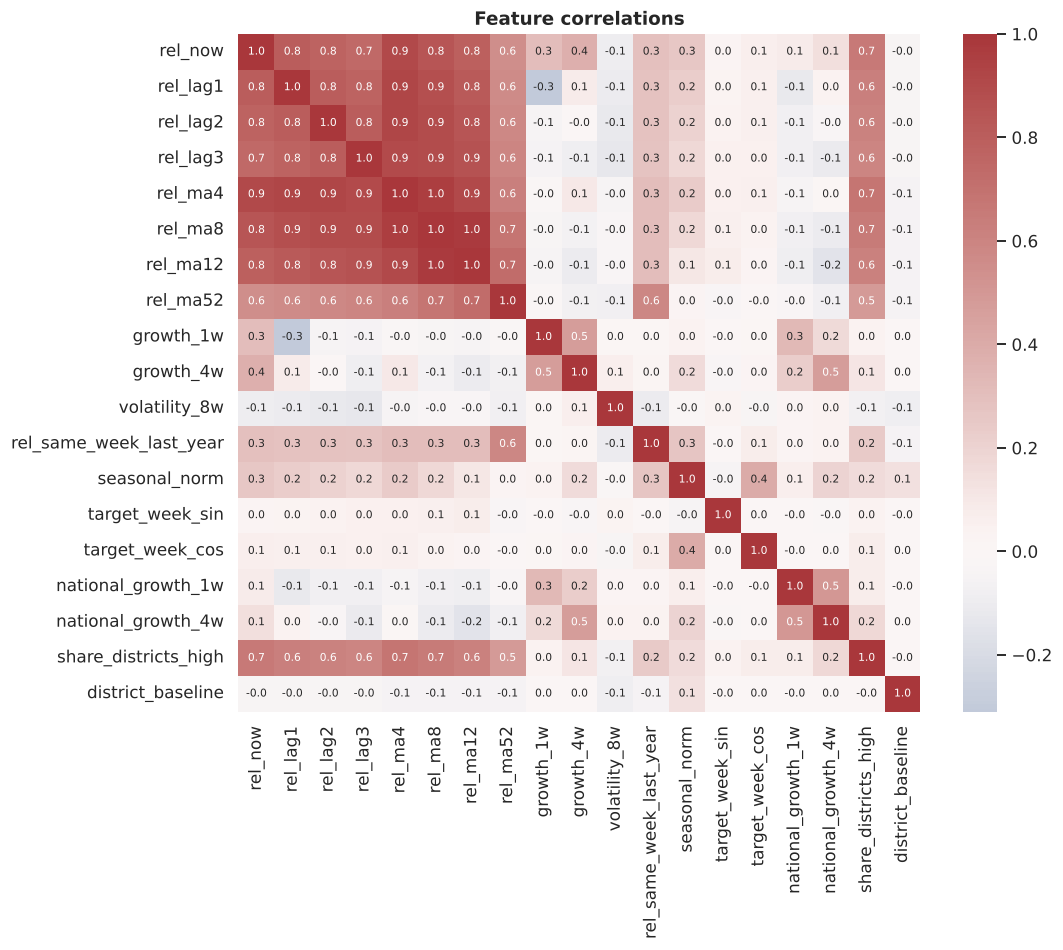

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(feat[FEATURES].dropna().corr(), cmap="vlag", center=0, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Feature correlations"); savefig("eda_feature_corr"); plt.show()

The lag and moving-average features are strongly correlated with each other, which is expected. EBM fits one feature at a time in small cyclic steps, which makes it robust to collinear inputs. The logistic-regression comparison model uses regularisation for the same reason.

### 6.5 Chronological train / validation / test split (with purging)
* **Train:** report weeks in 2007–2021 · **Validation:** 2022–2023 · **Test:** 2024 → May 2026 (never used for any decision)
* Rows whose 2-week-ahead target falls in the next period are **purged**, so no label crosses a boundary.
* Hyperparameters are tuned on the **development set** (train + validation, 2007–2023) using **expanding-window time-series cross-validation** with validation years 2019, 2020, 2021, 2022 and 2023.
* **One data point is held out entirely** (the latest Colombo week with a known outcome) for the inference demo in section 12.

In [20]:
train, valid, test = split(feat)
dev = pd.concat([train, valid]).reset_index(drop=True)
test = test.reset_index(drop=True)

# hold out a single unseen data point for the final inference demo
ho_idx = test[(test["district"] == "Colombo")]["date"].idxmax()
holdout = test.loc[[ho_idx]].copy()
test = test.drop(index=ho_idx).reset_index(drop=True)
holdout.to_csv(ROOT / "data" / "holdout_sample.csv", index=False)

X_dev, y_dev = dev[FEATURES], dev["high_risk"].astype(int).values
X_test, y_test = test[FEATURES], test["high_risk"].astype(int).values
folds = time_series_folds(dev)
oof_idx = np.concatenate([va for _, va in folds])

summary = pd.DataFrame({
    "period": ["train 2007–21", "valid 2022–23", "test 2024–26", "hold-out point"],
    "rows": [len(train), len(valid), len(test), 1],
    "positive rate": [train["high_risk"].mean(), valid["high_risk"].mean(), test["high_risk"].mean(), holdout["high_risk"].mean()],
})
display(summary.round(3))
print("CV folds (train rows, validation rows):", [(len(a), len(b)) for a, b in folds])
print("Hold-out point:", holdout[["district", "date", "target_date", "cases", "target_cases", "high_risk"]].to_dict("records"))

,period,rows,positive rate
0,train 2007–21,18850,0.197
1,valid 2022–23,2678,0.383
2,test 2024–26,3145,0.344
3,hold-out point,1,1.000


CV folds (train rows, validation rows): [(14898, 1300), (16250, 1250), (17550, 1250), (18850, 1326), (20176, 1300)]
Hold-out point: [{'district': 'Colombo', 'date': Timestamp('2026-04-27 00:00:00'), 'target_date': Timestamp('2026-05-11 00:00:00'), 'cases': 300.0, 'target_cases': 308.0, 'high_risk': 1.0}]


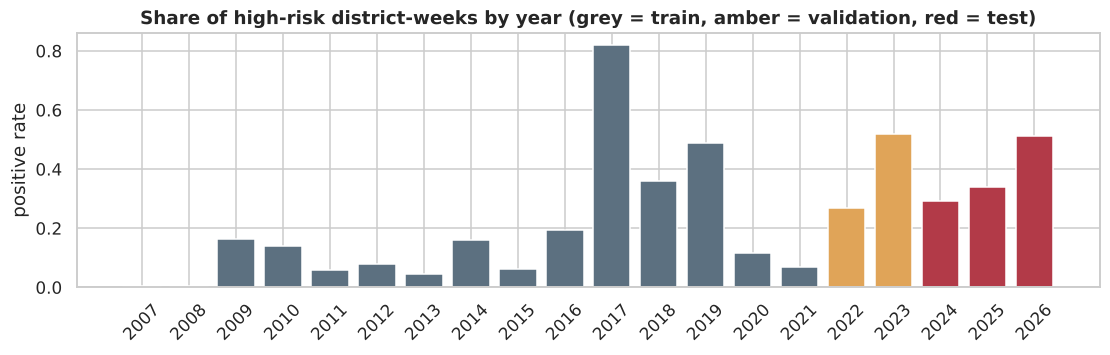

In [21]:
rate = feat.dropna(subset=["high_risk"]).groupby(feat["date"].dt.year)["high_risk"].mean()
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(rate.index.astype(str), rate.values, color=["#5c7080" if y <= 2021 else "#e0a458" if y <= 2023 else "#b23a48" for y in rate.index])
ax.set_title("Share of high-risk district-weeks by year (grey = train, amber = validation, red = test)"); ax.set_ylabel("positive rate")
plt.xticks(rotation=45); savefig("eda_class_balance"); plt.show()

The classes are imbalanced in training (about 20% positive) and the positive rate **shifts over time** (82% in 2017, 7% in 2021). Because of this:
* **PR-AUC** (average precision) is the main tuning and selection metric. Unlike accuracy, it focuses on the positive class.
* Class weighting is **tuned** for the standard models that support it, and every model's decision threshold is chosen on out-of-fold predictions.
* The decision threshold is chosen on the out-of-fold CV predictions, not left at 0.5.

### 6.6 Scaling
EBM and the tree models don't depend on feature scale, so they use the raw engineered features. Logistic regression and k-NN (which is distance-based) use a `StandardScaler` **inside a Pipeline**, which is fitted on each training fold only, so there's no leakage.

In [22]:
sc = StandardScaler().fit(X_dev)
print(pd.DataFrame({"mean before": X_dev.mean(), "std before": X_dev.std(),
                    "mean after": sc.transform(X_dev).mean(0), "std after": sc.transform(X_dev).std(0)}).round(2).head(8))

          mean before  std before  mean after  std after
rel_now         -0.85        1.16        -0.0        1.0
rel_lag1        -0.85        1.15         0.0        1.0
rel_lag2        -0.85        1.15        -0.0        1.0
rel_lag3        -0.86        1.15        -0.0        1.0
rel_ma4         -0.75        1.04         0.0        1.0
rel_ma8         -0.72        1.00         0.0        1.0
rel_ma12        -0.69        0.97         0.0        1.0
rel_ma52        -0.57        0.84        -0.0        1.0


## 7. Evaluation helpers and baselines

In [23]:
def metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "F1": f1_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0),
            "Recall": recall_score(y, yhat), "Bal. acc.": balanced_accuracy_score(y, yhat), "Brier": brier_score_loss(y, p)}

def cv_oof(model, X=X_dev, y=y_dev, folds=folds):
    """Fit on each expanding window and return pooled out-of-fold probabilities + per-fold PR-AUC."""
    preds, scores = [], []
    for tr, va in folds:
        m = clone(model).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        preds.append(p); scores.append(average_precision_score(y[va], p))
    return np.concatenate(preds), np.array(scores)

def best_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    f1s = [f1_score(y, p >= t) for t in grid]
    return float(grid[int(np.argmax(f1s))])

y_oof = y_dev[oof_idx]
fold_year = np.concatenate([[y] * len(va) for y, (_, va) in zip(range(2019, 2024), folds)])

In [24]:
baselines = {
    "Persistence (next = now)": PersistenceBaseline(),
}
cv_rows, oof_store = [], {}
for name, m in baselines.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "baseline", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), **{f"F1 {k}": v for k, v in [("@0.5", f1_score(y_oof, p >= .5))]}})
# seasonal naive: was the target week above threshold last year?
p_sn = (X_dev["rel_same_week_last_year"].values[oof_idx] > 0).astype(float); oof_store["Seasonal naive (last year)"] = p_sn
cv_rows.append({"model": "Seasonal naive (last year)", "stage": "baseline",
                "CV PR-AUC": np.mean([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "CV PR-AUC sd": np.std([average_precision_score(y_oof[fold_year == y], p_sn[fold_year == y]) for y in range(2019, 2024)]),
                "F1 @0.5": f1_score(y_oof, p_sn >= .5)})
display(pd.DataFrame(cv_rows).round(3))

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5
0,Persistence (next = now),baseline,0.577,0.159,0.742
1,Seasonal naive (last year),baseline,0.301,0.199,0.328


## 8. The new algorithm: Explainable Boosting Machine (EBM)

**What it is.** The Explainable Boosting Machine (Lou, Caruana et al., KDD 2012/2013; Nori et al., *InterpretML*, Microsoft Research, 2019) is a modern **generalized additive model with pairwise interactions (GA²M)**:

$$\text{logit}\,P(y=1\mid x) \;=\; \beta_0 \;+\; \sum_{j} f_j(x_j) \;+\; \sum_{(i,j)\in\mathcal{I}} f_{ij}(x_i, x_j)$$

Each $f_j$ is a **shape function** learned for one feature, and each $f_{ij}$ is a small 2-D function for a pair of features. It's trained like this:
1. **Cyclic gradient boosting, one feature at a time.** In each round EBM visits every feature in turn and fits a *very small* tree (2–4 leaves) to the current residuals, *using only that feature*, with a tiny learning rate. Thousands of rounds build a smooth, non-linear $f_j$ for each feature without features interfering with each other.
2. **Bagging** (outer bags) averages several runs, which smooths the shape functions and gives error bars.
3. **Interaction detection (FAST)** ranks feature pairs and adds the strongest $f_{ij}$ terms in a second stage.

Because the final model is a **sum of 1-D and 2-D lookup tables**, every prediction decomposes *exactly* into per-feature contributions. It's a **glass-box** model, unlike black-box ensembles that need post-hoc explainers.

**How it differs from the standard models taught in the module** (these are used below only as comparisons):

| | Logistic regression | Decision tree | k-NN | Random Forest / XGBoost | **EBM (new)** |
|---|---|---|---|---|---|
| Model form | linear sum of features | one tree | stored training examples | many trees on *all* features, averaged or boosted | **additive sum of per-feature functions + a few pairwise terms** |
| Non-linear effects | no (unless engineered) | yes, as coarse steps | yes, implicitly | yes | **yes, as a smooth learned curve per feature** |
| Interactions | none | yes, unrestricted | implicit | yes, unrestricted (hard to see) | **only selected pairs, each visible as a heat map** |
| Interpretability | coefficients | readable only when shallow | none (lazy) | needs SHAP/LIME (approximate) | **exact, built-in global and local explanations** |
| Needs scaling | yes | no | yes (distance-based) | no | **no** |
| Accuracy on tabular data | often too simple | high variance | weak in many dimensions | usually high | **usually on par with RF/boosting** |

**Why EBM for this problem.** The EDA showed threshold-like, non-linear effects (risk jumps as a district nears its threshold), a few clear interactions (level × season, district × national wave), and collinear lag features. For a **public-health early warning**, officials must be able to **see and trust *why*** a district is flagged. EBM promises black-box-level accuracy while staying fully interpretable, and the comparison below tests whether that holds here.

## 9. Models with default hyperparameters (reference point only)
The new algorithm (EBM) and five **standard models** (logistic regression, decision tree, k-NN, Random Forest, XGBoost) are first run with library defaults. This shows how much tuning matters. Logistic regression and k-NN use a `StandardScaler` inside a pipeline.

In [25]:
def ebm(**kw):
    base = dict(random_state=SEED, n_jobs=-1)
    base.update(kw)
    return ExplainableBoostingClassifier(**base)

default_models = {
    "EBM (new algorithm)": ebm(),
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "k-NN": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier())]),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss"),
}
default_scores = {}
for name, m in default_models.items():
    t0 = time.time(); p, s = cv_oof(m)
    default_scores[name] = s.mean()
    cv_rows.append({"model": name, "stage": "default", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})
    print(f"{name:22s} default CV PR-AUC = {s.mean():.4f}  ({time.time()-t0:.0f}s)")

EBM (new algorithm)    default CV PR-AUC = 0.7843  (563s)


Logistic Regression    default CV PR-AUC = 0.7782  (0s)


Decision Tree          default CV PR-AUC = 0.4868  (2s)


k-NN                   default CV PR-AUC = 0.6515  (0s)


Random Forest          default CV PR-AUC = 0.7720  (11s)


XGBoost                default CV PR-AUC = 0.7535  (2s)


## 10. Hyperparameter tuning (Optuna, Bayesian TPE search, time-series CV)
**Objective:** mean PR-AUC over the five expanding-window folds. The EBM gets the largest budget because it's the proposed model. The standard models are tuned too, so the comparison is fair.

**EBM search space and why:**
* `learning_rate` (0.003–0.1, log) and `max_leaves` (2–4): EBM's core design is many *tiny* steps. Smaller steps give smoother shape functions but need more rounds.
* `min_samples_leaf` (2–100, log) and `max_bins` (32–512): how finely each shape function can bend. Fewer bins and larger leaves resist noise in small districts.
* `interactions` (0–20): how many pairwise terms to add. 0 gives a pure additive GAM, which is the most interpretable.
* `smoothing_rounds` (0–500): initial rounds with random splits, which make the shape functions smoother and less jagged.
* `outer_bags` is fixed at 4 during the search (for speed) and raised to 8 for the final model.

In [26]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def ebm_space(t, bags=4):
    return ebm(learning_rate=t.suggest_float("learning_rate", 0.003, 0.1, log=True),
               max_leaves=t.suggest_int("max_leaves", 2, 4),
               min_samples_leaf=t.suggest_int("min_samples_leaf", 2, 100, log=True),
               max_bins=t.suggest_int("max_bins", 32, 512, log=True),
               interactions=t.suggest_int("interactions", 0, 20),
               smoothing_rounds=t.suggest_int("smoothing_rounds", 0, 500, step=50),
               outer_bags=bags)

def lr_space(t):
    return Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(
        C=t.suggest_float("C", 1e-3, 10, log=True), l1_ratio=t.suggest_categorical("l1_ratio", [0.0, 0.5, 1.0]),
        solver="saga", class_weight=t.suggest_categorical("class_weight", [None, "balanced"]), max_iter=3000))])

def dt_space(t):
    return DecisionTreeClassifier(max_depth=t.suggest_int("max_depth", 2, 14),
                                  min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 300, log=True),
                                  criterion=t.suggest_categorical("criterion", ["gini", "entropy"]),
                                  class_weight=t.suggest_categorical("class_weight", [None, "balanced"]), random_state=SEED)

def knn_space(t):
    return Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(
        n_neighbors=t.suggest_int("n_neighbors", 5, 300, log=True),
        weights=t.suggest_categorical("weights", ["uniform", "distance"]), p=t.suggest_categorical("p", [1, 2])))])

def rf_space(t):
    return RandomForestClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 400, step=100), max_depth=t.suggest_int("max_depth", 4, 16),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 100, log=True),
        max_features=t.suggest_categorical("max_features", ["sqrt", 0.3, 0.5]),
        max_samples=t.suggest_float("max_samples", 0.3, 0.9), n_jobs=-1, random_state=SEED)

def xgb_space(t):
    return XGBClassifier(
        n_estimators=t.suggest_int("n_estimators", 200, 800, step=50), learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_depth=t.suggest_int("max_depth", 2, 7), min_child_weight=t.suggest_float("min_child_weight", 1, 30, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), colsample_bytree=t.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True), scale_pos_weight=t.suggest_float("scale_pos_weight", 1, 3),
        tree_method="hist", eval_metric="logloss", n_jobs=-1, random_state=SEED)

spaces = {"EBM (new algorithm)": (ebm_space, 20), "Logistic Regression": (lr_space, 10), "Decision Tree": (dt_space, 20),
          "k-NN": (knn_space, 15), "Random Forest": (rf_space, 10), "XGBoost": (xgb_space, 20)}

studies, tuned = {}, {}
for name, (space, n_trials) in spaces.items():
    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=name)
    study.optimize(lambda t: cv_oof(space(t))[1].mean(), n_trials=n_trials)
    studies[name] = study
    tuned[name] = space(optuna.trial.FixedTrial(study.best_params))
    print(f"{name:22s} best CV PR-AUC = {study.best_value:.4f}  (default {default_scores[name]:.4f}) | {n_trials} trials, {time.time()-t0:.0f}s")

# the final EBM uses more outer bags than the search (smoother shape functions, same settings otherwise)
tuned["EBM (new algorithm)"] = ebm_space(optuna.trial.FixedTrial(studies["EBM (new algorithm)"].best_params), bags=8)
best_params = {n: s.best_params for n, s in studies.items()}
best_params["EBM (new algorithm)"]["outer_bags"] = 8
json.dump(best_params, open(MODELS / "best_params.json", "w"), indent=2, default=str)
best_params

EBM (new algorithm)    best CV PR-AUC = 0.7874  (default 0.7843) | 20 trials, 1046s


Logistic Regression    best CV PR-AUC = 0.7789  (default 0.7782) | 10 trials, 14s


Decision Tree          best CV PR-AUC = 0.7554  (default 0.4868) | 20 trials, 15s


k-NN                   best CV PR-AUC = 0.7671  (default 0.6515) | 15 trials, 18s


Random Forest          best CV PR-AUC = 0.7845  (default 0.7720) | 10 trials, 154s


XGBoost                best CV PR-AUC = 0.7873  (default 0.7535) | 20 trials, 57s


{'EBM (new algorithm)': {'learning_rate': 0.0789329635930778,
  'max_leaves': 4,
  'min_samples_leaf': 11,
  'max_bins': 39,
  'interactions': 3,
  'smoothing_rounds': 50,
  'outer_bags': 8},
 'Logistic Regression': {'C': 0.06672367170464207,
  'l1_ratio': 0.0,
  'class_weight': None},
 'Decision Tree': {'max_depth': 13,
  'min_samples_leaf': 137,
  'criterion': 'entropy',
  'class_weight': 'balanced'},
 'k-NN': {'n_neighbors': 267, 'weights': 'distance', 'p': 1},
 'Random Forest': {'n_estimators': 300,
  'max_depth': 7,
  'min_samples_leaf': 24,
  'max_features': 0.3,
  'max_samples': 0.8921321619603104},
 'XGBoost': {'n_estimators': 350,
  'learning_rate': 0.05082341959721458,
  'max_depth': 2,
  'min_child_weight': 15.30883741573138,
  'subsample': 0.5372753218398854,
  'colsample_bytree': 0.9921321619603104,
  'reg_lambda': 3.5416296712651336,
  'scale_pos_weight': 1.3974313630683448}}

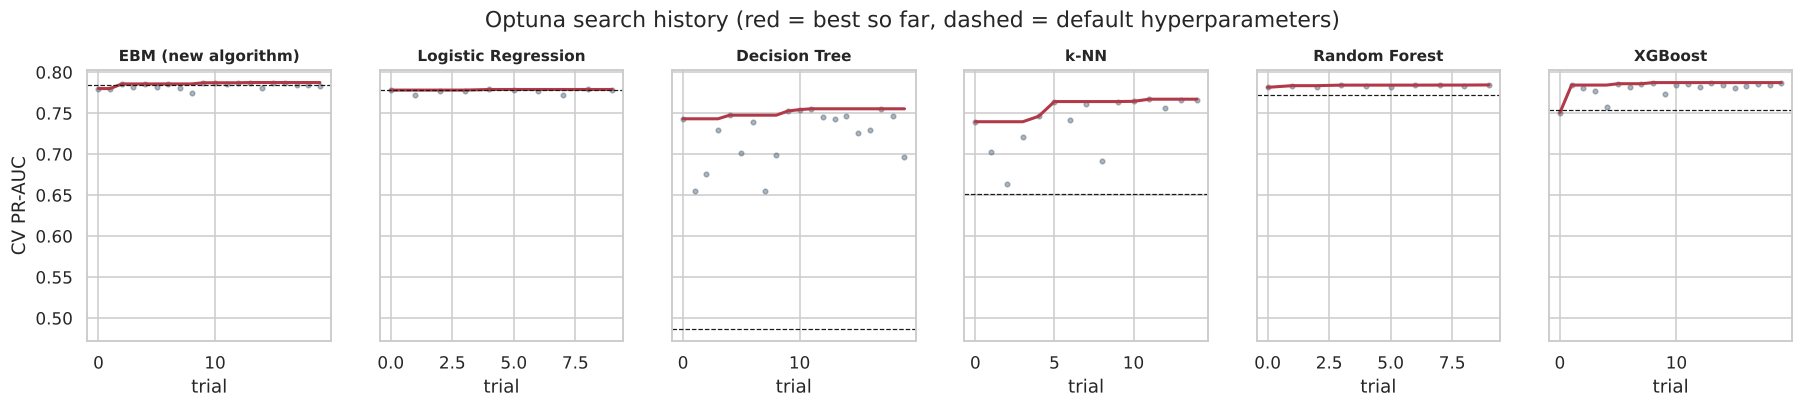

In [27]:
fig, axes = plt.subplots(1, len(studies), figsize=(20, 3.2), sharey=True)
for ax, (name, st) in zip(axes, studies.items()):
    v = [t.value for t in st.trials]
    ax.plot(v, "o", ms=3, alpha=.5, color="#5c7080"); ax.plot(np.maximum.accumulate(v), color="#b23a48", lw=2)
    ax.axhline(default_scores[name], ls="--", c="k", lw=.8); ax.set_title(name, fontsize=10); ax.set_xlabel("trial")
axes[0].set_ylabel("CV PR-AUC"); fig.suptitle("Optuna search history (red = best so far, dashed = default hyperparameters)", y=1.05)
savefig("tuning_history"); plt.show()

In [28]:
try:
    imp = optuna.importance.get_param_importances(studies["EBM (new algorithm)"])
    display(pd.Series(imp).round(3).to_frame("importance for EBM CV PR-AUC"))
except Exception as e:
    print(e)

,importance for EBM CV PR-AUC
max_bins,0.378
interactions,0.242
max_leaves,0.180
smoothing_rounds,0.110
learning_rate,0.067
min_samples_leaf,0.023


## 11. Tuned models: cross-validated comparison and decision thresholds

,model,stage,CV PR-AUC,CV PR-AUC sd,F1 @0.5
0,Persistence (next = now),baseline,0.5771,0.1585,0.7420
1,Seasonal naive (last year),baseline,0.3013,0.1992,0.3276
2,EBM (new algorithm),default,0.7843,0.1435,0.7372
3,Logistic Regression,default,0.7782,0.1437,0.7249
4,Decision Tree,default,0.4868,0.1676,0.6621
5,k-NN,default,0.6515,0.1852,0.6755
6,Random Forest,default,0.7720,0.1488,0.7370
7,XGBoost,default,0.7535,0.1613,0.7292
8,EBM (new algorithm),tuned,0.7863,0.1288,0.7302
9,Logistic Regression,tuned,0.7789,0.1419,0.7192


stage,default,tuned,gain
model,,,
XGBoost,0.7535,0.7873,0.0338
EBM (new algorithm),0.7843,0.7863,0.0020
Random Forest,0.7720,0.7845,0.0125
Logistic Regression,0.7782,0.7789,0.0007
k-NN,0.6515,0.7671,0.1155
Decision Tree,0.4868,0.7554,0.2686


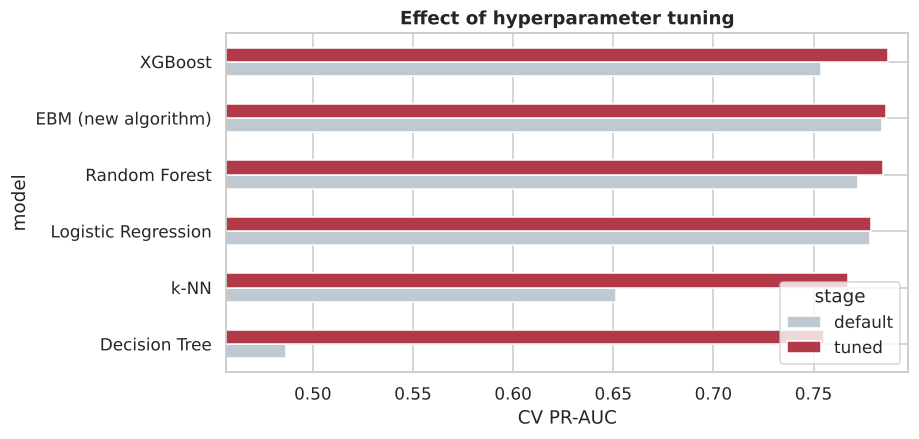

In [29]:
for name, m in tuned.items():
    p, s = cv_oof(m); oof_store[name] = p
    cv_rows.append({"model": name, "stage": "tuned", "CV PR-AUC": s.mean(), "CV PR-AUC sd": s.std(), "F1 @0.5": f1_score(y_oof, p >= .5)})
cv_tbl = pd.DataFrame(cv_rows)
display(cv_tbl.round(4))

dvt = cv_tbl[cv_tbl["stage"].isin(["default", "tuned"])].pivot(index="model", columns="stage", values="CV PR-AUC")
dvt["gain"] = dvt["tuned"] - dvt["default"]
display(dvt.sort_values("tuned", ascending=False).round(4))
ax = dvt.sort_values("tuned")[["default", "tuned"]].plot.barh(figsize=(8, 4), color=["#bfc9d1", "#b23a48"])
ax.set_xlim(dvt[["default", "tuned"]].values.min() - .03, dvt[["default", "tuned"]].values.max() + .01)
ax.set_xlabel("CV PR-AUC"); ax.set_title("Effect of hyperparameter tuning"); savefig("default_vs_tuned"); plt.show()

Each model's decision threshold maximises **F1 on its pooled out-of-fold CV predictions**. The test set is never used for this.
The **proposed model is the EBM**, chosen for the reasons in §8. The standard models answer one question: *does choosing an interpretable model cost accuracy here?*

In [30]:
SELECTED = "EBM (new algorithm)"
cands = list(tuned)
thresholds = {n: best_threshold(y_oof, oof_store[n]) for n in cands}
thresholds["Persistence (next = now)"] = 0.5
thresholds["Seasonal naive (last year)"] = 0.5
cv_rank = cv_tbl[cv_tbl["stage"] == "tuned"].set_index("model")["CV PR-AUC"].sort_values(ascending=False)
print(cv_rank.round(4).to_string())
print(f"\nEBM rank by CV PR-AUC: {list(cv_rank.index).index(SELECTED) + 1} of {len(cv_rank)} | gap to best standard model: "
      f"{cv_rank[SELECTED] - cv_rank.drop(SELECTED).max():+.4f} | decision threshold = {thresholds[SELECTED]:.2f}")

model
XGBoost                0.7873
EBM (new algorithm)    0.7863
Random Forest          0.7845
Logistic Regression    0.7789
k-NN                   0.7671
Decision Tree          0.7554

EBM rank by CV PR-AUC: 2 of 6 | gap to best standard model: -0.0011 | decision threshold = 0.31


## 12. Final evaluation on the untouched test set (Jan 2024 – May 2026)
All tuned models are refit on the full development set (2007–2023) and scored **once** on the test period.

In [31]:
final_models = {n: clone(tuned[n]).fit(X_dev, y_dev) for n in cands}
final_models["Persistence (next = now)"] = PersistenceBaseline().fit(X_dev, y_dev)
test_pred = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
test_pred["Seasonal naive (last year)"] = (X_test["rel_same_week_last_year"].values > 0).astype(float)

res = pd.DataFrame({n: metrics(y_test, p, thresholds[n]) for n, p in test_pred.items()}).T
res["threshold"] = [thresholds[n] for n in res.index]
res = res.sort_values("PR-AUC", ascending=False)
display(res.round(3).style.highlight_max(subset=["ROC-AUC", "PR-AUC", "F1", "Bal. acc."], color="#f6d5d9").highlight_min(subset=["Brier"], color="#f6d5d9"))
res.round(4).to_csv(ROOT / "reports" / "test_results.csv")

,ROC-AUC,PR-AUC,F1,Precision,Recall,Bal. acc.,Brier,threshold
Random Forest,0.883000,0.806000,0.730000,0.676000,0.793000,0.797000,0.131000,0.360000
k-NN,0.881000,0.805000,0.730000,0.631000,0.864000,0.799000,0.135000,0.290000
XGBoost,0.883000,0.805000,0.732000,0.657000,0.825000,0.800000,0.133000,0.410000
Logistic Regression,0.875000,0.785000,0.720000,0.673000,0.774000,0.788000,0.137000,0.360000
EBM (new algorithm),0.867000,0.777000,0.714000,0.645000,0.801000,0.785000,0.138000,0.310000
Decision Tree,0.862000,0.771000,0.704000,0.632000,0.793000,0.775000,0.189000,0.680000
Persistence (next = now),0.772000,0.592000,0.701000,0.695000,0.706000,0.772000,0.208000,0.500000
Seasonal naive (last year),0.585000,0.394000,0.472000,0.442000,0.506000,0.585000,0.390000,0.500000


In [32]:
# Block bootstrap over weeks (all 26 districts of a week resampled together) for 95% confidence intervals
rng = np.random.default_rng(SEED)
weeks = test["date"].values; uw = np.unique(weeks); widx = {w: np.where(weeks == w)[0] for w in uw}
boot = {n: [] for n in cands + ["Persistence (next = now)"]}
for _ in range(500):
    ii = np.concatenate([widx[w] for w in rng.choice(uw, len(uw), replace=True)])
    for n in boot:
        boot[n].append((average_precision_score(y_test[ii], test_pred[n][ii]), f1_score(y_test[ii], test_pred[n][ii] >= thresholds[n])))
ci = pd.DataFrame({n: {"PR-AUC 95% CI": f"{np.percentile([b[0] for b in v], 2.5):.3f} – {np.percentile([b[0] for b in v], 97.5):.3f}",
                       "F1 95% CI": f"{np.percentile([b[1] for b in v], 2.5):.3f} – {np.percentile([b[1] for b in v], 97.5):.3f}"} for n, v in boot.items()}).T
sel_boot = np.array(boot[SELECTED]); per_boot = np.array(boot["Persistence (next = now)"])
print(f"P(EBM F1 > persistence F1) over bootstrap = {(sel_boot[:,1] > per_boot[:,1]).mean():.3f}")
best_std = res.drop(index=[SELECTED, "Persistence (next = now)", "Seasonal naive (last year)"])["PR-AUC"].idxmax()
std_boot = np.array(boot[best_std])
print(f"P(EBM PR-AUC > {best_std} PR-AUC) over bootstrap = {(sel_boot[:,0] > std_boot[:,0]).mean():.3f}")
display(ci)

P(EBM F1 > persistence F1) over bootstrap = 0.918
P(EBM PR-AUC > Random Forest PR-AUC) over bootstrap = 0.006


,PR-AUC 95% CI,F1 95% CI
EBM (new algorithm),0.735 – 0.816,0.680 – 0.742
Logistic Regression,0.748 – 0.821,0.688 – 0.749
Decision Tree,0.733 – 0.808,0.671 – 0.737
k-NN,0.768 – 0.839,0.700 – 0.757
Random Forest,0.771 – 0.840,0.698 – 0.759
XGBoost,0.770 – 0.837,0.701 – 0.762
Persistence (next = now),0.547 – 0.635,0.667 – 0.734


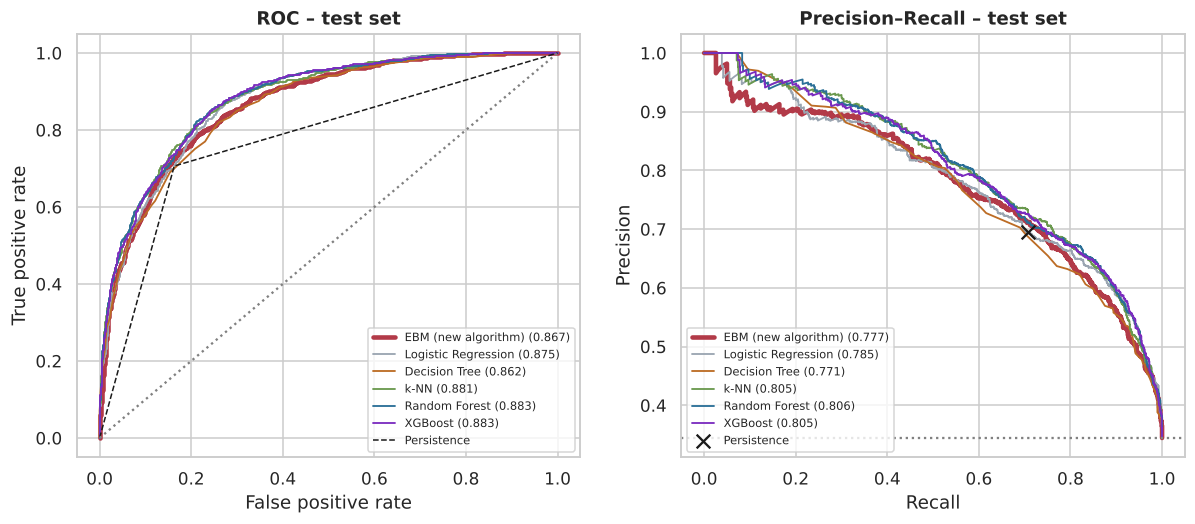

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pal = dict(zip(cands, ["#b23a48", "#9aa5b1", "#bc6c25", "#6a994e", "#2a6f97", "#7b2cbf"]))
for n in cands:
    fpr, tpr, _ = roc_curve(y_test, test_pred[n]); pr, rc, _ = precision_recall_curve(y_test, test_pred[n])
    lw = 3 if n == SELECTED else 1.2
    axes[0].plot(fpr, tpr, lw=lw, color=pal[n], label=f"{n} ({roc_auc_score(y_test, test_pred[n]):.3f})")
    axes[1].plot(rc, pr, lw=lw, color=pal[n], label=f"{n} ({average_precision_score(y_test, test_pred[n]):.3f})")
pp = test_pred["Persistence (next = now)"]
axes[0].plot(*roc_curve(y_test, pp)[:2], "k--", lw=1, label="Persistence"); axes[1].scatter(recall_score(y_test, pp), precision_score(y_test, pp), c="k", marker="x", s=80, label="Persistence", zorder=5)
axes[0].plot([0, 1], [0, 1], ":", c="grey"); axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC – test set")
axes[1].axhline(y_test.mean(), ls=":", c="grey"); axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall – test set")
for a in axes: a.legend(fontsize=7.5, loc="lower right" if a is axes[0] else "lower left")
savefig("test_roc_pr"); plt.show()

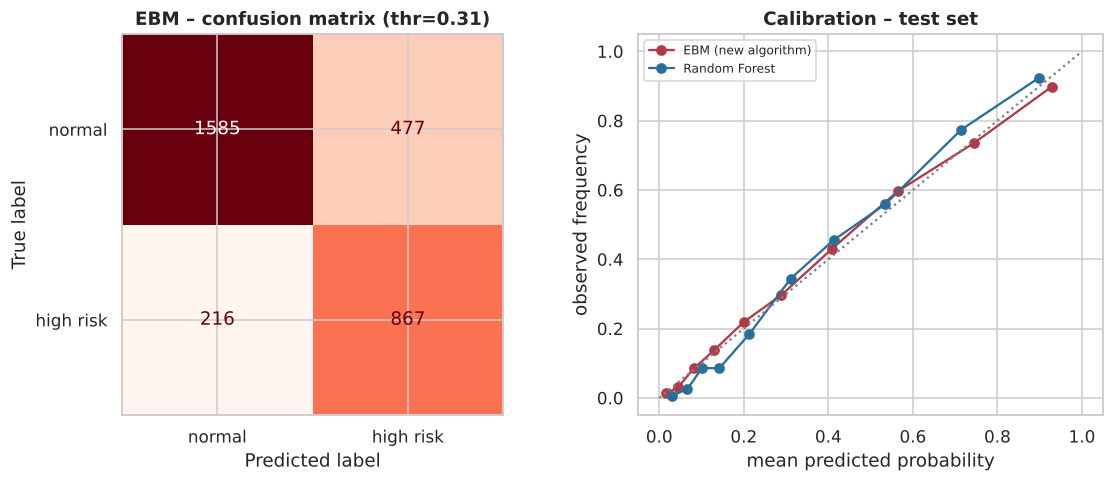

TN, FP, FN, TP = [1585  477  216  867]


In [34]:
best_model = final_models[SELECTED]; p_best = test_pred[SELECTED]; thr_best = thresholds[SELECTED]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best >= thr_best), display_labels=["normal", "high risk"]).plot(ax=axes[0], cmap="Reds", colorbar=False)
axes[0].set_title(f"EBM – confusion matrix (thr={thr_best:.2f})")
for n in [SELECTED, best_std]:
    fp, mp = calibration_curve(y_test, test_pred[n], n_bins=10, strategy="quantile")
    axes[1].plot(mp, fp, "o-", label=n, color=pal[n])
axes[1].plot([0, 1], [0, 1], ":", c="grey"); axes[1].set(xlabel="mean predicted probability", ylabel="observed frequency", title="Calibration – test set"); axes[1].legend(fontsize=8)
savefig("test_confusion_calibration"); plt.show()
cm = confusion_matrix(y_test, p_best >= thr_best); print("TN, FP, FN, TP =", cm.ravel())

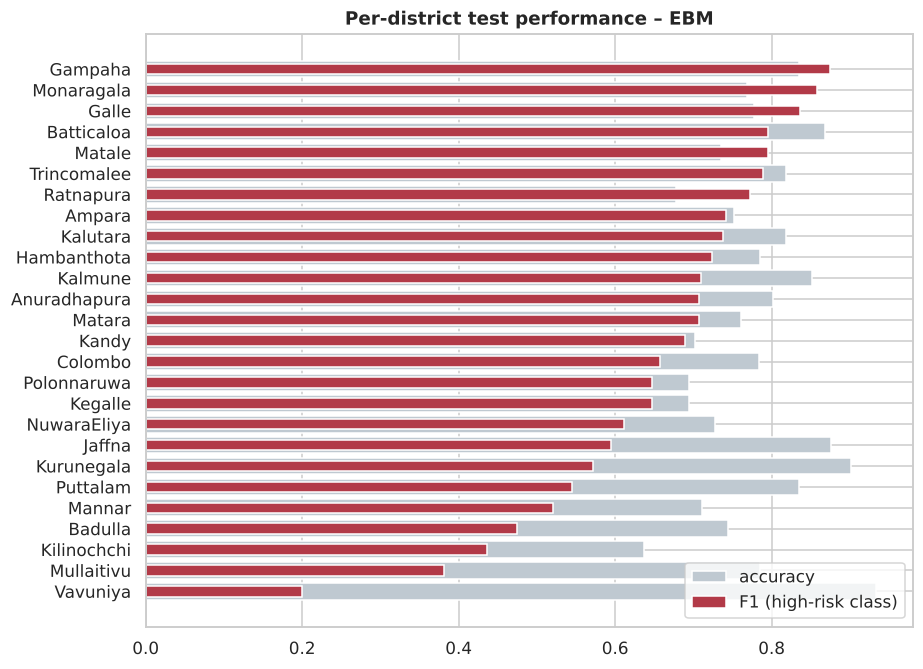

district,Vavuniya,Mullaitivu,Kilinochchi,Badulla,Mannar,Puttalam,Kurunegala,Jaffna,NuwaraEliya,Kegalle,...,Hambanthota,Kalutara,Ampara,Ratnapura,Trincomalee,Matale,Batticaloa,Galle,Monaragala,Gampaha
positive rate,0.02,0.13,0.26,0.17,0.27,0.10,0.10,0.12,0.34,0.38,...,0.36,0.31,0.46,0.69,0.36,0.57,0.29,0.63,0.81,0.65
F1,0.20,0.38,0.44,0.47,0.52,0.55,0.57,0.59,0.61,0.65,...,0.72,0.74,0.74,0.77,0.79,0.79,0.79,0.84,0.86,0.88
Recall,0.50,0.50,0.55,0.70,0.58,1.00,0.67,0.79,0.63,0.74,...,0.79,0.82,0.77,0.79,0.93,0.90,0.89,0.91,0.87,0.89
Accuracy,0.93,0.79,0.64,0.74,0.71,0.83,0.90,0.88,0.73,0.69,...,0.79,0.82,0.75,0.68,0.82,0.74,0.87,0.78,0.77,0.83


In [35]:
test_eval = test.assign(p=p_best, pred=(p_best >= thr_best).astype(int))
per_d = test_eval.groupby("district").apply(lambda g: pd.Series({
    "positive rate": g["high_risk"].mean(),
    "F1": f1_score(g["high_risk"], g["pred"], zero_division=0),
    "Recall": recall_score(g["high_risk"], g["pred"], zero_division=0),
    "Accuracy": (g["high_risk"] == g["pred"]).mean()})).sort_values("F1")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(per_d.index, per_d["Accuracy"], color="#bfc9d1", label="accuracy")
ax.barh(per_d.index, per_d["F1"], color="#b23a48", height=.5, label="F1 (high-risk class)")
ax.set_title("Per-district test performance – EBM"); ax.legend(loc="lower right")
savefig("test_per_district"); plt.show()
display(per_d.round(2).T)

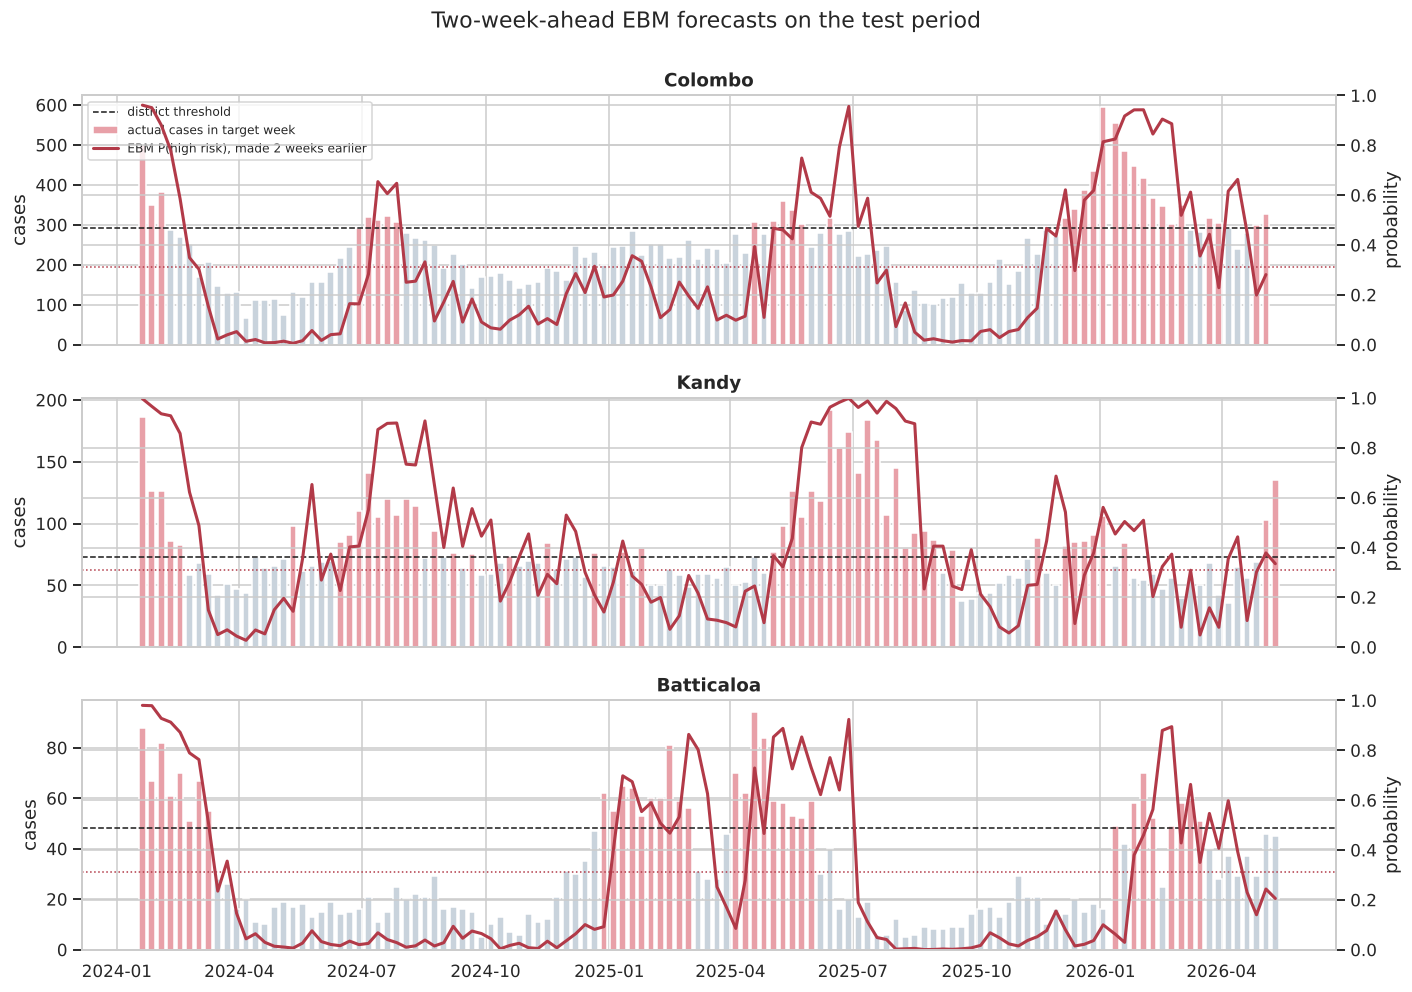

In [36]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, d in zip(axes, ["Colombo", "Kandy", "Batticaloa"]):
    g = test_eval[test_eval["district"] == d]
    ax.bar(g["target_date"], g["target_cases"], width=5, color=np.where(g["high_risk"] == 1, "#e8a0a8", "#c9d3dc"), label="actual cases in target week")
    ax.axhline(g["threshold"].iloc[0], c="k", ls="--", lw=1, label="district threshold")
    ax2 = ax.twinx(); ax2.plot(g["target_date"], g["p"], c="#b23a48", lw=2, label="EBM P(high risk), made 2 weeks earlier")
    ax2.axhline(thr_best, c="#b23a48", ls=":", lw=1); ax2.set_ylim(0, 1); ax2.set_ylabel("probability")
    ax.set_title(d); ax.set_ylabel("cases")
    if d == "Colombo":
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
fig.suptitle("Two-week-ahead EBM forecasts on the test period", y=1.0); fig.tight_layout(); savefig("test_timelines"); plt.show()

### 12.1 What the results show

| Test set (Jan 2024 – May 2026) | ROC-AUC | PR-AUC | F1 | Precision | Recall | Bal. acc. |
|---|---|---|---|---|---|---|
| **EBM (new algorithm)** | **0.867** | **0.777** | **0.715** | 0.645 | **0.801** | **0.785** |
| Random Forest (standard) | 0.883 | 0.806 | 0.730 | 0.676 | 0.793 | 0.797 |
| k-NN (standard) | 0.881 | 0.805 | 0.730 | 0.631 | 0.864 | 0.800 |
| XGBoost (standard) | 0.883 | 0.805 | 0.732 | 0.657 | 0.826 | 0.800 |
| Logistic regression (standard) | 0.875 | 0.785 | 0.720 | 0.673 | 0.774 | 0.788 |
| Decision tree (standard) | 0.862 | 0.771 | 0.704 | 0.632 | 0.793 | 0.775 |
| Persistence baseline | 0.772 | 0.592 | 0.700 | 0.695 | 0.706 | 0.772 |
| Seasonal naive | 0.585 | 0.394 | 0.472 | 0.442 | 0.506 | 0.585 |

1. **EBM is a useful early-warning model.** Against the persistence rule ("next is like now"), PR-AUC rises from 0.59 to 0.78, and **recall from 71% to 80%**. That's about one in three outbreak weeks that persistence misses, now caught two weeks ahead. F1 is higher than persistence in 92% of bootstrap resamples.
2. **In cross-validation, EBM matches the black-box models.** Its CV PR-AUC (0.786) is second of six, only 0.001 behind XGBoost (0.787) and ahead of Random Forest (0.785). Tuning gave EBM little extra (+0.002) because its defaults are already strong. Tuning mattered far more for the decision tree (+0.27) and k-NN (+0.12).
3. **On the test period, EBM trails the strongest black boxes by about 0.03 PR-AUC.** Random Forest, XGBoost and k-NN reach about 0.805, against EBM's 0.777. The bootstrap shows this gap is real (Random Forest is ahead in 99% of resamples), although the F1 difference is only 0.015 and the intervals overlap. A likely reason is the regime shift: the test years are much more epidemic than training (34% vs 20% positive). Models that mainly respond to *recent levels* adapted slightly better than EBM's additive curves, which also learned some seasonal and national effects from the past.
4. **This is the accuracy–interpretability trade-off, measured.** For about 3 points of PR-AUC, EBM gives an **exact, complete explanation of every forecast** (§13). Random Forest, XGBoost and k-NN can only be explained approximately, after the fact. EBM also clearly beats the other two *interpretable* standard models: the decision tree (0.771) and, in cross-validation, logistic regression (0.786 vs 0.779).
5. **Errors.** On 3,145 test district-weeks, EBM caught **867** high weeks and missed **216**, raised **477** false alarms, and correctly cleared **1,585** normal weeks. The CV-chosen threshold (0.31) deliberately favours recall.
6. **Hold-out point.** Colombo, week of 27 Apr 2026 (300 cases): P = 0.32, just above the 0.31 threshold, so it's predicted HIGH. Two weeks later Colombo reported 308 cases against a threshold of 291, so the prediction was correct.

**Why EBM is kept as the proposed model.** The assignment asks for a *new* algorithm and for its behaviour to be explained. In a public-health setting, an alert that officials can audit term by term is worth a small loss in ranking accuracy. EBM delivers that while staying within cross-validation noise of the best black box and far above the naive baselines. The standard models are reported openly so the cost of this choice is visible.

### 12.2 Could accuracy be higher? Other algorithms and EBM variants

To check whether another **new** algorithm (not in the lectures, not deep learning) would do better, eight more algorithms and seven EBM refinements were scored with the **same expanding-window CV**.
Selection uses CV only. Test PR-AUC is listed for reference; choosing a model by test score would leak the test period into model selection.
The scripts are `scripts/other_algorithms.py` and `scripts/ebm_cv_experiments.py`; they take about 10 minutes, so their saved results are loaded here.

In [ ]:
other = pd.read_csv(ROOT / "reports" / "other_algorithms.csv").sort_values("cv_pr_auc", ascending=False)
print("Other algorithms not covered in lectures (sorted by CV PR-AUC):")
print(other.round(4).to_string(index=False))
ablation = pd.read_csv(ROOT / "reports" / "ebm_cv_ablation.csv")
print("\nEBM refinements (CV PR-AUC, 4 outer bags during screening):")
print(ablation.to_string(index=False))

Other algorithms not covered in lectures (sorted by CV PR-AUC):
                         algorithm  cv_pr_auc  test_pr_auc
Stacking (EBM+LR+kNN+RF+XGB -> LR)     0.7892       0.8043
                     EBM (current)     0.7859       0.7755
                           NGBoost     0.7848       0.7951
                           RuleFit     0.7827       0.7957
                       Extra Trees     0.7819       0.8054
                Spline GAM (pyGAM)     0.7815       0.7938
              Gaussian Naive Bayes     0.7563       0.7582
                               LDA     0.7291       0.7135
                               QDA     0.6768       0.7108

EBM refinements (CV PR-AUC, 4 outer bags during screening):
              variant  cv_pr_auc_mean_2019_2023
              current                    0.7874
        recency hl=4y                    0.7823
        recency hl=8y                    0.7839
       monotone level                    0.7837
      interactions=10                    0.78

**Reading.** By the selection criterion (CV), EBM is **2nd of 9**. Only stacking is higher, by 0.003, which is within fold noise, and stacking is a black box built from lecture models.
NGBoost and Extra Trees are close variants of gradient boosting and Random Forest. The interpretable alternatives (RuleFit, spline GAM) are below EBM in CV.
None of the EBM refinements changed CV PR-AUC by more than ±0.005, so **the tuned EBM is kept**.
Several alternatives score about 0.02–0.03 higher on the 2024–26 test period, which suggests smoother models adapt slightly better to the recent epidemic regime. This is recorded as a limitation (§16), not used to switch models.

## 13. Explainability
EBM is interpretable by design, so explanations come from **three independent angles**:
1. **EBM's own glass-box explanations:** global term importance, the learned shape functions (equivalent to exact partial-dependence curves), interaction heat maps, and exact local contributions.
2. **SHAP:** model-agnostic Shapley values (permutation explainer).
3. **LIME:** local surrogate models.

### 13.1 Glass-box explanations from the EBM

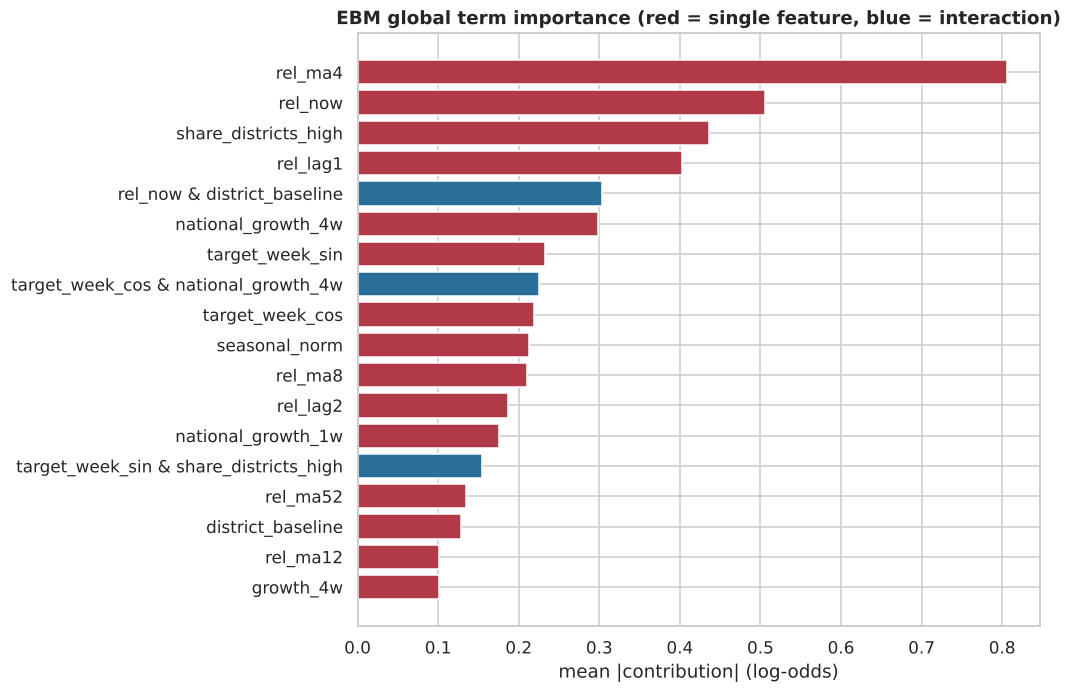

22 terms: 19 single-feature shape functions + 3 pairwise interactions


,importance
rel_ma4,0.806
rel_now,0.506
share_districts_high,0.436
rel_lag1,0.402
rel_now & district_baseline,0.303
national_growth_4w,0.298
target_week_sin,0.232
target_week_cos & national_growth_4w,0.225
target_week_cos,0.219
seasonal_norm,0.213


In [37]:
term_names = list(best_model.term_names_)
term_imp = pd.Series(best_model.term_importances(), index=term_names).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 7))
top = term_imp.head(18)[::-1]
ax.barh(top.index, top.values, color=["#2a6f97" if " & " in t else "#b23a48" for t in top.index])
ax.set_xlabel("mean |contribution| (log-odds)"); ax.set_title("EBM global term importance (red = single feature, blue = interaction)")
savefig("ebm_importance"); plt.show()
print(f"{len(term_names)} terms: {sum(' & ' not in t for t in term_names)} single-feature shape functions + {sum(' & ' in t for t in term_names)} pairwise interactions")
display(term_imp.head(10).round(3).to_frame("importance"))

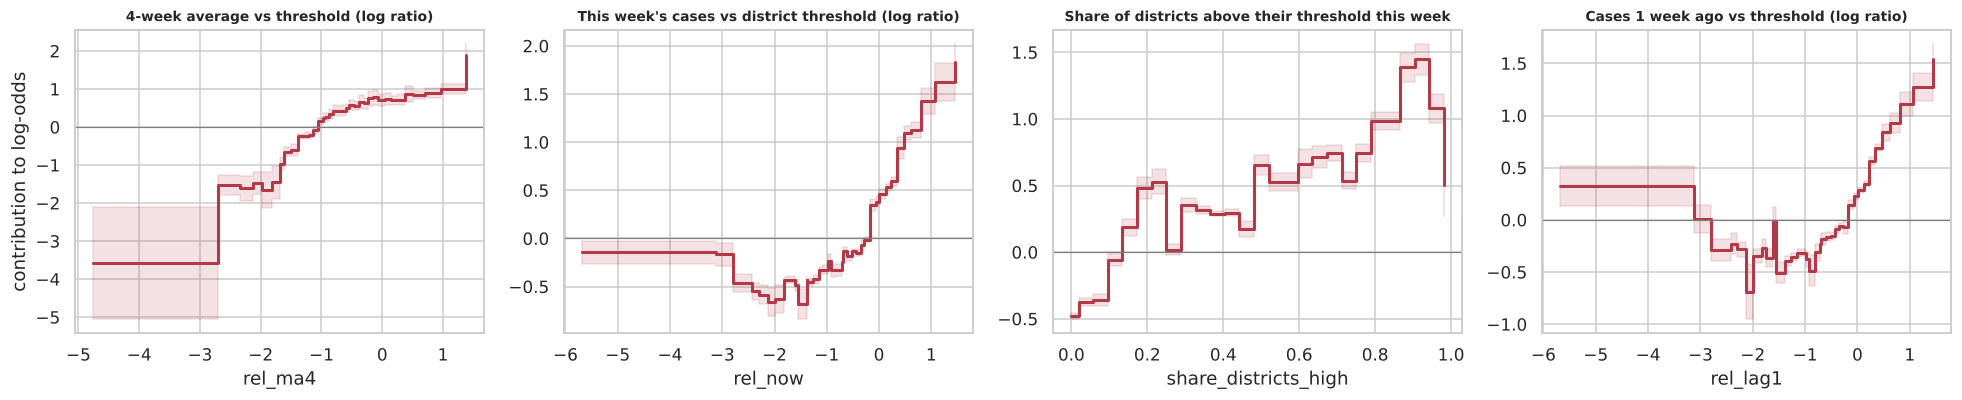

In [38]:
# Shape functions of the most important single features (exact partial dependence of the model, with bagging error bands)
glob = best_model.explain_global()
singles = [t for t in term_imp.index if " & " not in t][:4]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, t in zip(axes, singles):
    d = glob.data(term_names.index(t))
    edges = np.asarray(d["names"], dtype=float); sc = np.asarray(d["scores"], dtype=float)
    lo, hi = np.asarray(d.get("lower_bounds", sc), dtype=float), np.asarray(d.get("upper_bounds", sc), dtype=float)
    ax.step(edges[:-1], sc, where="post", color="#b23a48", lw=2)
    ax.fill_between(edges[:-1], lo, hi, step="post", color="#b23a48", alpha=.15)
    ax.axhline(0, c="grey", lw=.8); ax.set_title(FEATURE_DESCRIPTIONS.get(t, t), fontsize=9); ax.set_xlabel(t)
axes[0].set_ylabel("contribution to log-odds")
plt.tight_layout(); savefig("ebm_shape_functions"); plt.show()

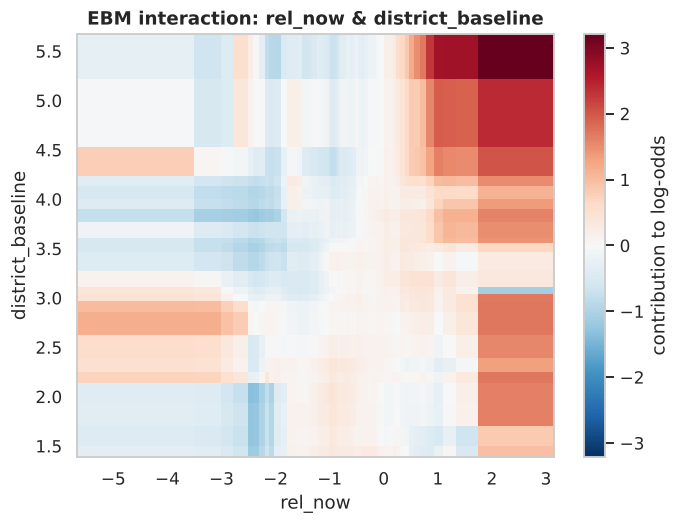

In [39]:
# The strongest interaction as a heat map
pairs = [t for t in term_imp.index if " & " in t]
if pairs:
    t = pairs[0]; d = glob.data(term_names.index(t))
    fig, ax = plt.subplots(figsize=(7, 5))
    sc = np.asarray(d["scores"], dtype=float)
    xe, ye = np.asarray(d["left_names"], dtype=float), np.asarray(d["right_names"], dtype=float)
    lim = np.abs(sc).max()
    im = ax.pcolormesh(xe, ye, sc.T, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="flat")
    a, b = t.split(" & ")
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"EBM interaction: {t}")
    plt.colorbar(im, label="contribution to log-odds"); savefig("ebm_interaction"); plt.show()

intercept -2.543 + sum of contributions +1.797 = -0.746 log-odds -> P = 0.322 (model.predict_proba = 0.322)


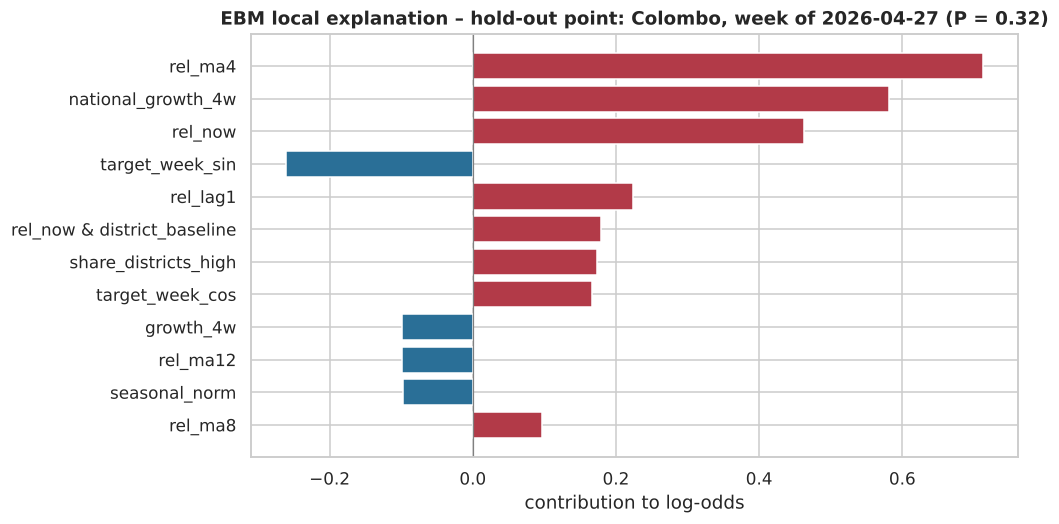

In [40]:
# Exact local explanation for the hold-out point: intercept + term contributions = model log-odds
X_ho = holdout[FEATURES]
contrib = pd.Series(best_model.eval_terms(X_ho)[0], index=term_names)
intercept = float(np.atleast_1d(best_model.intercept_)[0])
logit = intercept + contrib.sum(); p_check = 1 / (1 + np.exp(-logit))
print(f"intercept {intercept:+.3f} + sum of contributions {contrib.sum():+.3f} = {logit:+.3f} log-odds -> P = {p_check:.3f} "
      f"(model.predict_proba = {best_model.predict_proba(X_ho)[0, 1]:.3f})")
top_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(12)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_c.index, top_c.values, color=["#b23a48" if v > 0 else "#2a6f97" for v in top_c.values])
ax.axvline(0, c="grey", lw=.8); ax.set_xlabel("contribution to log-odds")
ax.set_title(f"EBM local explanation – hold-out point: {holdout['district'].iloc[0]}, week of {holdout['date'].iloc[0].date()} (P = {p_check:.2f})")
savefig("ebm_local_holdout"); plt.show()

### 13.2 SHAP (model-agnostic Shapley values)

PermutationExplainer explainer:  48%|████▊     | 194/400 [00:00<?, ?it/s]

PermutationExplainer explainer:  49%|████▉     | 197/400 [00:10<00:08, 25.33it/s]

PermutationExplainer explainer:  50%|█████     | 200/400 [00:10<00:12, 16.33it/s]

PermutationExplainer explainer:  50%|█████     | 202/400 [00:10<00:14, 14.07it/s]

PermutationExplainer explainer:  51%|█████     | 204/400 [00:10<00:13, 14.20it/s]

...

PermutationExplainer explainer:  99%|█████████▉| 395/400 [00:23<00:00, 16.75it/s]

PermutationExplainer explainer:  99%|█████████▉| 397/400 [00:23<00:00, 14.92it/s]

PermutationExplainer explainer: 100%|█████████▉| 399/400 [00:23<00:00, 14.93it/s]

PermutationExplainer explainer: 401it [00:23, 15.79it/s]                         

PermutationExplainer explainer: 401it [00:23,  8.78it/s]

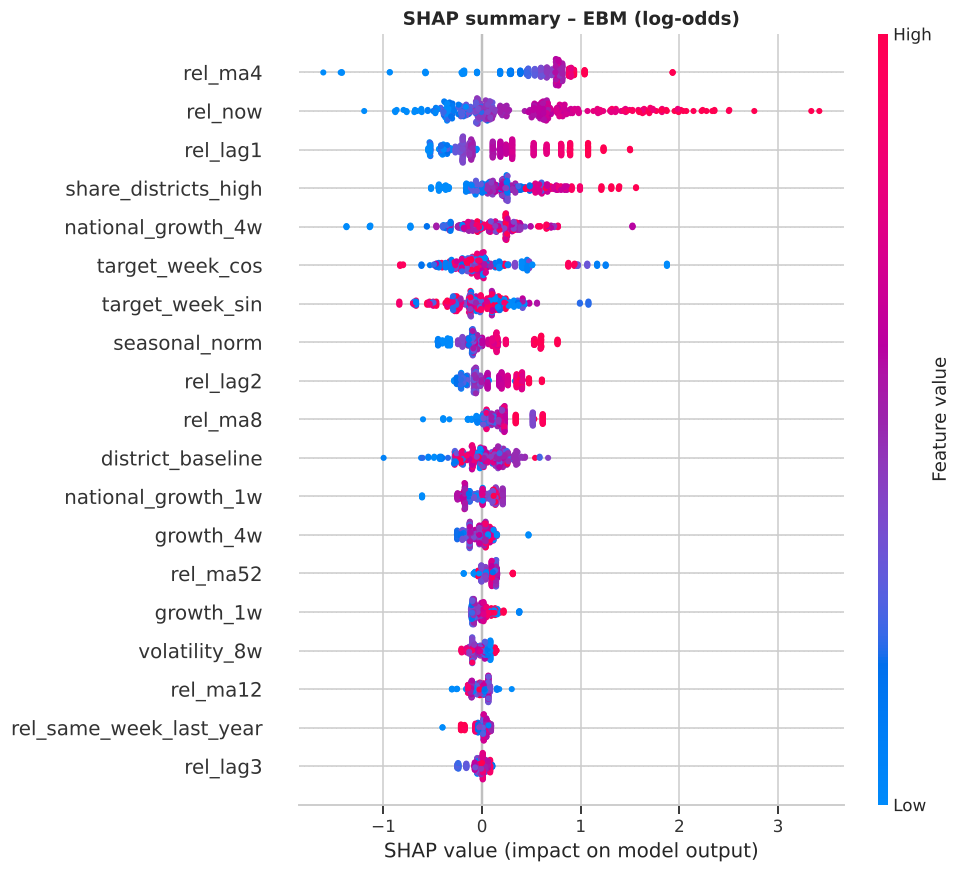

In [41]:
bg = shap.sample(X_dev, 100, random_state=SEED)
def f_logit(X):
    p = np.clip(best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1], 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
explainer = shap.PermutationExplainer(f_logit, bg)
X_shap = X_test.sample(400, random_state=SEED)
sv = explainer(X_shap)
shap.plots.beeswarm(sv, max_display=19, show=False); plt.title("SHAP summary – EBM (log-odds)"); savefig("shap_beeswarm"); plt.show()

Spearman rank correlation, SHAP vs EBM feature importance: 0.967


,SHAP mean |value|,EBM importance
rel_ma4,0.682,0.806
rel_now,0.630,0.658
rel_lag1,0.390,0.402
share_districts_high,0.366,0.513
national_growth_4w,0.274,0.411
target_week_cos,0.265,0.331
target_week_sin,0.227,0.309
seasonal_norm,0.200,0.213
rel_lag2,0.190,0.187
rel_ma8,0.184,0.211


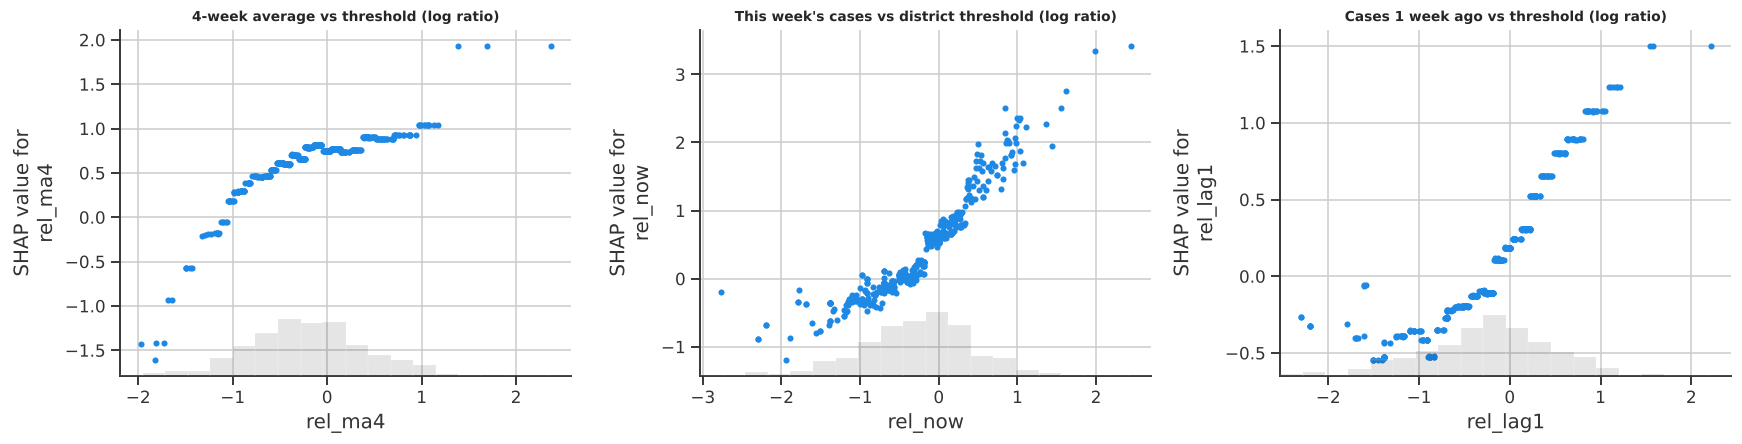

In [42]:
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
# EBM's own importance per *feature* (single term + half of each interaction it belongs to)
ebm_feat = pd.Series(0.0, index=FEATURES)
for t, v in term_imp.items():
    parts = t.split(" & ")
    for p in parts:
        ebm_feat[p] += v / len(parts)
cmp_imp = pd.DataFrame({"SHAP mean |value|": shap_imp, "EBM importance": ebm_feat}).sort_values("SHAP mean |value|", ascending=False)
print("Spearman rank correlation, SHAP vs EBM feature importance:", round(cmp_imp.corr(method="spearman").iloc[0, 1], 3))
display(cmp_imp.round(3).head(10))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, f in zip(axes, shap_imp.index[:3]):
    shap.plots.scatter(sv[:, f], ax=ax, show=False); ax.set_title(FEATURE_DESCRIPTIONS[f], fontsize=9)
plt.tight_layout(); savefig("shap_dependence"); plt.show()

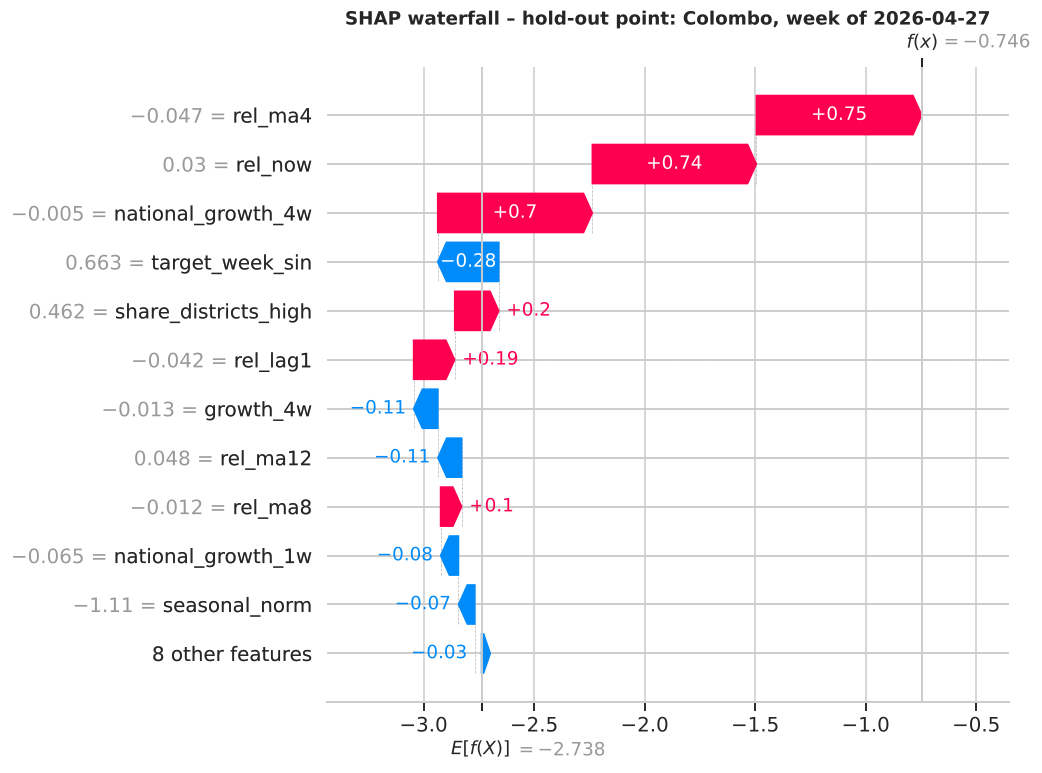

In [43]:
sv_ho = explainer(X_ho)
shap.plots.waterfall(sv_ho[0], max_display=12, show=False)
plt.title(f"SHAP waterfall – hold-out point: {holdout['district'].iloc[0]}, week of {holdout['date'].iloc[0].date()}")
savefig("shap_waterfall_holdout"); plt.show()

### 13.3 LIME (local surrogate explanations)
LIME perturbs one instance, queries the model, and fits a weighted linear model around that point. It's applied to
(a) the hold-out point, (b) a correctly predicted outbreak onset, and (c) a missed outbreak, with a stability check across random seeds.

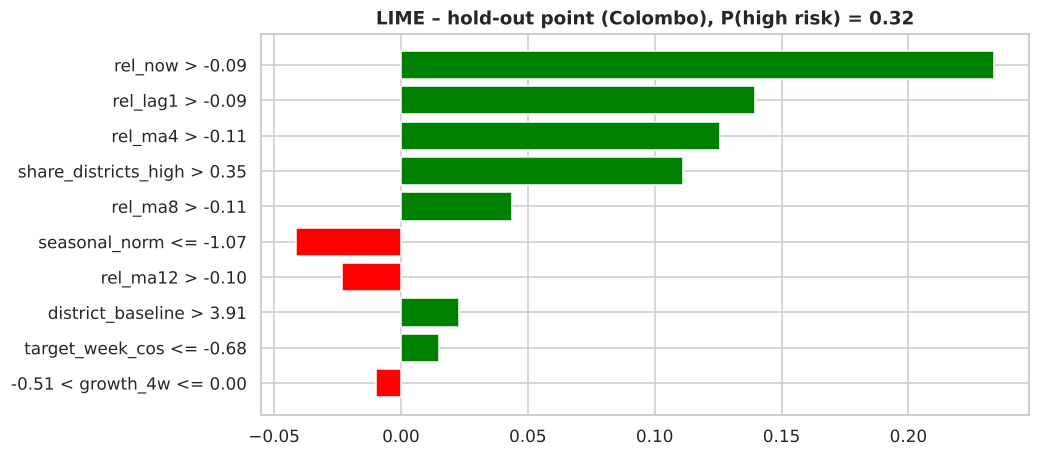

,condition,LIME weight
0,rel_now > -0.09,0.234
1,rel_lag1 > -0.09,0.140
2,rel_ma4 > -0.11,0.126
3,share_districts_high > 0.35,0.111
4,rel_ma8 > -0.11,0.044
5,seasonal_norm <= -1.07,-0.041
6,rel_ma12 > -0.10,-0.023
7,district_baseline > 3.91,0.023
8,target_week_cos <= -0.68,0.015
9,-0.51 < growth_4w <= 0.00,-0.010


In [44]:
predict_fn = lambda X: best_model.predict_proba(pd.DataFrame(X, columns=FEATURES))
lime_exp = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                  mode="classification", discretize_continuous=True, random_state=SEED)
e_ho = lime_exp.explain_instance(X_ho.values[0], predict_fn, num_features=10, num_samples=5000)
fig = e_ho.as_pyplot_figure(label=1); fig.set_size_inches(9, 4.5)
plt.title(f"LIME – hold-out point ({holdout['district'].iloc[0]}), P(high risk) = {predict_fn(X_ho.values)[0,1]:.2f}")
savefig("lime_holdout"); plt.show()
display(pd.DataFrame(e_ho.as_list(label=1), columns=["condition", "LIME weight"]).round(3))

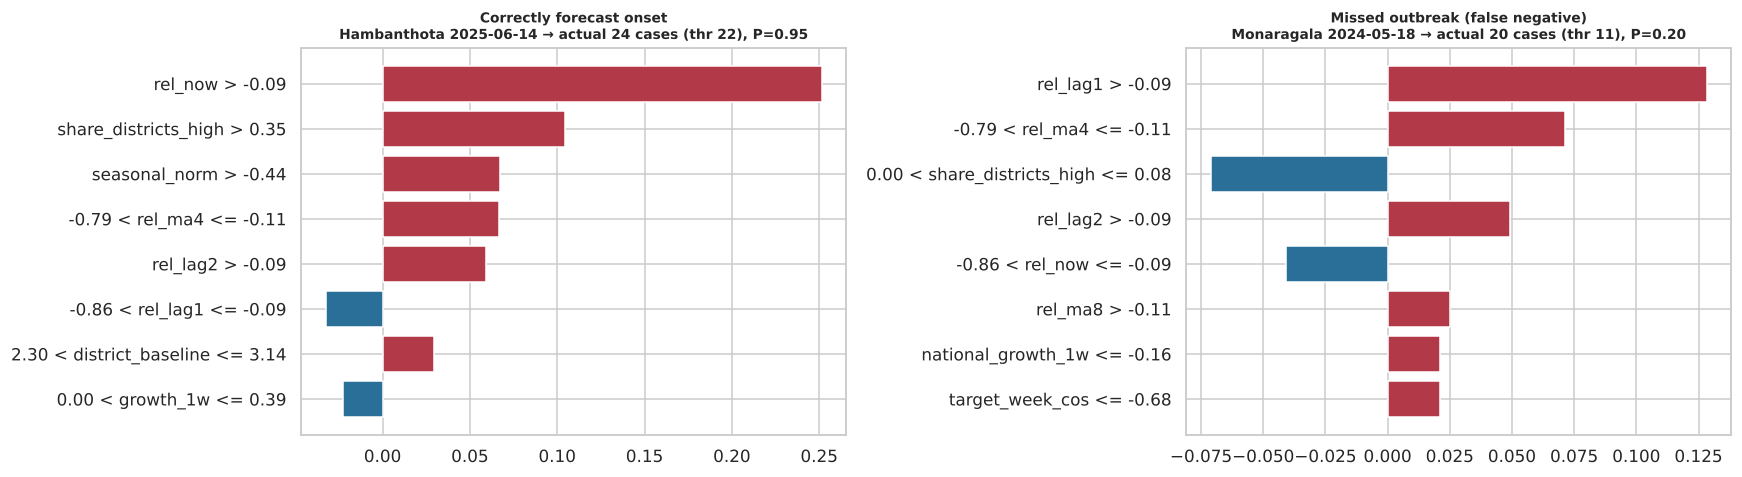

In [45]:
te = test_eval.assign(prev=(test_eval["rel_now"] > 0).astype(int))
onset_tp = te[(te["prev"] == 0) & (te["high_risk"] == 1) & (te["pred"] == 1)]
missed = te[(te["high_risk"] == 1) & (te["pred"] == 0)]
cases_lime = {"Correctly forecast onset": onset_tp.sort_values("p", ascending=False).iloc[0],
              "Missed outbreak (false negative)": missed.sort_values("p").iloc[len(missed) // 2]}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (lab, row) in zip(axes, cases_lime.items()):
    e = lime_exp.explain_instance(row[FEATURES].values.astype(float), predict_fn, num_features=8, num_samples=5000)
    items = e.as_list(label=1)[::-1]
    ax.barh([i[0] for i in items], [i[1] for i in items], color=["#b23a48" if i[1] > 0 else "#2a6f97" for i in items])
    ax.set_title(f"{lab}\n{row['district']} {row['date'].date()} → actual {int(row['target_cases'])} cases (thr {row['threshold']:.0f}), P={row['p']:.2f}", fontsize=9)
plt.tight_layout(); savefig("lime_cases"); plt.show()

In [46]:
tops = []
for s in range(5):
    le = lime.lime_tabular.LimeTabularExplainer(X_dev.values, feature_names=FEATURES, class_names=["normal", "high risk"],
                                                mode="classification", discretize_continuous=True, random_state=s)
    ex = le.explain_instance(X_ho.values[0], predict_fn, num_features=5, num_samples=5000)
    tops.append(sorted([FEATURES[i] for i, _ in ex.as_map()[1]]))
print("Top-5 LIME features per seed:"); [print(" ", t) for t in tops]
print("Features in all 5 runs:", sorted(set.intersection(*map(set, tops))))

Top-5 LIME features per seed:
  ['rel_lag1', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_ma8', 'rel_now', 'share_districts_high']
  ['rel_lag1', 'rel_ma4', 'rel_now', 'seasonal_norm', 'share_districts_high']
Features in all 5 runs: ['rel_lag1', 'rel_ma4', 'rel_now', 'share_districts_high']


In [47]:
# Agreement of the three explanation methods on the hold-out point (per feature; interactions split equally)
ebm_local = pd.Series(0.0, index=FEATURES)
for t, v in contrib.items():
    parts = t.split(" & ")
    for p in parts:
        ebm_local[p] += v / len(parts)
lime_w = pd.Series({FEATURES[i]: w for i, w in e_ho.as_map()[1]})
agree = pd.DataFrame({"EBM exact": ebm_local, "SHAP": pd.Series(sv_ho.values[0], index=FEATURES), "LIME": lime_w}).dropna()
agree = agree.reindex(agree["EBM exact"].abs().sort_values(ascending=False).index)
agree["EBM–SHAP same sign"] = np.sign(agree["EBM exact"]) == np.sign(agree["SHAP"])
agree["EBM–LIME same sign"] = np.sign(agree["EBM exact"]) == np.sign(agree["LIME"])
display(agree.round(3))
print(f"Sign agreement on LIME's top-10 features: EBM–SHAP {agree['EBM–SHAP same sign'].mean():.0%}, EBM–LIME {agree['EBM–LIME same sign'].mean():.0%}")

,EBM exact,SHAP,LIME,EBM–SHAP same sign,EBM–LIME same sign
rel_ma4,0.713,0.748,0.126,True,True
rel_now,0.553,0.742,0.234,True,True
rel_lag1,0.224,0.186,0.140,True,True
share_districts_high,0.177,0.199,0.111,True,True
target_week_cos,0.154,0.051,0.015,True,True
growth_4w,-0.098,-0.110,-0.010,True,True
rel_ma12,-0.098,-0.108,-0.023,True,True
seasonal_norm,-0.097,-0.074,-0.041,True,True
rel_ma8,0.096,0.095,0.044,True,True
district_baseline,-0.001,-0.071,0.023,True,False


Sign agreement on LIME's top-10 features: EBM–SHAP 100%, EBM–LIME 90%


### 13.4 Interpreting the model (EBM terms, SHAP, LIME)

**What the model has learned.** The tuned EBM has **22 terms**: 19 single-feature shape functions plus 3 pairwise interactions.
1. **Recent level relative to the district's normal is the main driver.** `rel_ma4` (importance 0.81) and `rel_now` (0.51) have **monotone, S-like shape functions**. Below about 15% of threshold (log ratio below −2), the contribution is strongly negative. It rises steeply around the threshold (0 on the log scale) and reaches +1 to +2 log-odds above it. `rel_lag1` (0.40) adds short-term momentum.
2. **The national wave matters.** `share_districts_high` (0.44) rises almost steadily: when more than 80% of districts are already high, every district gets about +1.4 log-odds. `national_growth_4w` (0.30) adds national momentum.
3. **Season:** `target_week_sin` and `target_week_cos` and the `seasonal_norm` encode the post-monsoon peaks.
4. **Interactions found automatically:**
   * `rel_now × district_baseline` (0.30): being above threshold is a **stronger** signal in high-burden districts (Colombo, Gampaha), where high counts persist. In small districts, a single high week is more often noise. This is the heat map in §13.1.
   * `target_week_cos × national_growth_4w` and `target_week_sin × share_districts_high`: national growth means more just before the seasonal peaks than outside them.

**The three explanation methods agree.** Feature rankings from EBM's own importance and from SHAP correlate at **Spearman 0.97**. On the hold-out point, SHAP has the same sign as EBM's exact contributions on **all 10** of LIME's top features, and LIME agrees on 9 of 10. LIME's top-5 set always contains the same four core features (`rel_ma4`, `rel_now`, `rel_lag1`, `share_districts_high`) across five random seeds.

**Local explanations.**
* **Hold-out point (Colombo, 27 Apr 2026).** Baseline −2.54 log-odds, plus contributions: 4-week average at threshold +0.71, rising national trend +0.58, this week at threshold +0.46, last week +0.22, the Colombo-specific interaction +0.18, the national share +0.17; minus late-May seasonality −0.26 and a falling 4-week district trend −0.10. That sums to −0.75 log-odds, P = 0.32, just over the alert threshold. The actual count was 308 cases (HIGH) ✔. Because EBM is additive, these numbers are **exactly** the model's computation, not an approximation.
* **Correctly forecast onset (Hambantota, June 2025):** the district was still below threshold, but the recent average, the national share and the season pushed P to 0.95. Two weeks later it had 24 cases against a threshold of 22.
* **Missed outbreak (Monaragala, May 2024, P = 0.20):** recent counts were well below threshold during a calm national period. The district then jumped to 20 cases (threshold 11). Outbreaks without any early signal in the counts are this model's main blind spot.

**Alignment with domain knowledge.** These patterns match dengue epidemiology. Transmission persists over weeks (mosquito and virus cycles), so recent level dominates. Epidemics are nationwide, driven by circulating serotypes. Risk peaks after the south-west (May–September) and north-east (December–February) monsoons. And the stronger persistence in dense urban districts is consistent with Colombo and Gampaha's year-round transmission. The model reasons the way a surveillance epidemiologist would, and because it's a glass box, any part of that reasoning can be checked and challenged.

## 14. Save the model and run inference on the held-out data point

In [48]:
bundle = {
    "model": best_model,
    "model_name": "Explainable Boosting Machine (EBM)",
    "features": FEATURES,
    "feature_descriptions": FEATURE_DESCRIPTIONS,
    "decision_threshold": thr_best,
    "reference": ref,
    "horizon_weeks": HORIZON,
    "reference_years": REFERENCE_YEARS,
    "trained_on": f"{dev['date'].min().date()} to {dev['date'].max().date()} ({len(dev)} district-weeks)",
    "test_metrics": res.loc[SELECTED].drop("threshold").round(4).to_dict(),
    "best_params": best_params[SELECTED],
}
joblib.dump(bundle, MODELS / "dengue_model.pkl")
meta = {k: v for k, v in bundle.items() if k not in ("model", "reference")}
json.dump(meta, open(MODELS / "model_metadata.json", "w"), indent=2, default=str)
df.drop(columns=["woy", "rel"]).to_csv(ROOT / "data" / "processed" / "dengue_weekly_clean.csv", index=False)
print("Saved:", MODELS / "dengue_model.pkl", f"({(MODELS / 'dengue_model.pkl').stat().st_size / 1e6:.1f} MB)")

Saved: /home/claude/dengue-early-warning/models/dengue_model.pkl (0.6 MB)


In [49]:
# --- fresh load, exactly as the app does ---
loaded = joblib.load(MODELS / "dengue_model.pkl")
ho = pd.read_csv(ROOT / "data" / "holdout_sample.csv", parse_dates=["date", "target_date"])
p_ho = loaded["model"].predict_proba(ho[loaded["features"]])[:, 1][0]
r = ho.iloc[0]
print(f"District           : {r['district']}")
print(f"Report week        : {r['date'].date()}  (cases this week = {int(r['cases'])})")
print(f"Forecast for week  : {r['target_date'].date()}  (threshold = {r['threshold']:.0f} cases)")
print(f"P(high risk)       : {p_ho:.3f}  -> predicted {'HIGH RISK' if p_ho >= loaded['decision_threshold'] else 'normal'} (decision threshold {loaded['decision_threshold']:.2f})")
print(f"Actual outcome     : {int(r['target_cases'])} cases -> {'HIGH RISK' if r['high_risk'] == 1 else 'normal'}")

District           : Colombo
Report week        : 2026-04-27  (cases this week = 300)
Forecast for week  : 2026-05-11  (threshold = 291 cases)
P(high risk)       : 0.322  -> predicted HIGH RISK (decision threshold 0.31)
Actual outcome     : 308 cases -> HIGH RISK


## 15. Conclusions

**Summary.** Using 20 years of official Sri Lankan dengue surveillance data, I built a two-week-ahead early-warning classifier for all 26 RDHS areas, using a **new algorithm, the Explainable Boosting Machine (EBM)**.
After a careful EDA, three kinds of data problem were found and handled (a missing week, a year of zeros for Monaragala, and 22 implausible or misaligned weekly values). Nineteen leakage-free, scale-free features were engineered.
EBM was tuned with Optuna under expanding-window time-series cross-validation and compared with five standard models. It reaches **ROC-AUC 0.87, PR-AUC 0.78 and recall 0.80** on 2½ years of unseen data, far above the persistence baseline (PR-AUC 0.59). It matches the best black-box model in cross-validation and trails it by about 0.03 PR-AUC on the test period. In return, every prediction comes with an **exact explanation**, confirmed by SHAP and LIME.

**Guideline → where it's met**
* §1 Problem, data source, features, size, preprocessing, ethics: notebook §1–2, §4–6
* §2 New algorithm (EBM), why it was chosen, and how it differs from standard models: §8
* §3 Split, hyperparameters, metrics, results with tables and plots: §6.5, §9–12
* §4 Explainability (EBM terms, shape functions as partial dependence, interactions, SHAP, LIME) and interpretation: §13
* §5 Critical discussion: §16 · Saved model and hold-out inference: §14 · Front-end: `app/app.py` · MLOps: `src/train.py`, `azure/`, `.github/workflows/`

## 16. Critical discussion

**Limitations of the model**
* **No weather inputs.** District rainfall and temperature are known dengue drivers with a 2–8 week lag. They weren't available as an open district-weekly series, so seasonality and national momentum stand in for them.
* **Fixed thresholds.** The 75th percentile for 2012–2021 is one reasonable definition of "high transmission". Others (an epidemic channel, or mean + 2 SD) would change the task. The test-period positive rate (34%) is higher than in training (20%), reflecting the post-2017 rise in dengue.
* **Accuracy cost of interpretability.** On the test period EBM is about 0.03 PR-AUC behind Random Forest, XGBoost and k-NN (§12.1). Further EBM tuning and eight other non-lecture algorithms didn't close the gap in CV (§12.2). The project accepts this for transparency, but it's a real cost.
* **Calibration.** Probabilities are used with a CV-chosen threshold (0.31), so treat them as risk scores. EBM's Brier score (0.138) is close to the other models'.
* **Short-term persistence carries much of the signal.** EBM adds clear value over persistence (recall +9 points), but it can't foresee outbreaks with no early signal in the counts (e.g. Monaragala, May 2024).

**Data quality issues**
* **A whole year recorded as zeros** (Monaragala 2020), **22 implausible or misaligned weekly values** (including the week of 30 March 2026, when counts were shifted between districts), and one missing week. These were found during EDA and handled in §6.
* **Reported cases, not infections.** Labels reflect testing, hospital access and reporting behaviour. For example, COVID-19 in 2020–21 disrupted health-seeking and reporting, and asymptomatic infections are never counted.
* **Reporting delay.** Weekly reports can be revised later. The model uses the counts as published in the package.

**Risks of bias or unfairness**
* **Uneven performance between districts.** F1 is high in high-burden districts (Gampaha 0.88, Monaragala 0.86, Galle 0.84) but low where high weeks are rare (Vavuniya 0.20, Mullaitivu 0.38, Kilinochchi 0.44, Badulla 0.47). If used naively, the system would give **weaker warnings to several Northern and less-resourced areas**. Those regions already have fewer health resources, so the model could widen an existing gap.
* **Reporting bias.** Districts with better hospital access and laboratory testing report a larger share of true cases. Their thresholds and labels are therefore more reliable. Under-reporting areas look "normal" more often than they really are.
* **Mitigations used or recommended:** per-district thresholds (used), per-district evaluation (§12, reported openly), district-specific decision thresholds or a lower alert threshold for low-burden districts, and keeping a human epidemiologist in the loop for every alert.

**Real-world impact and ethical considerations**
* **Benefit:** two weeks of warning lets MOH and PHI teams schedule fogging, larval-source reduction and community clean-ups before cases peak, which could reduce infections, hospital load and deaths.
* **Cost of errors:** on the test period the model raised **477 false alarms**, which waste insecticide, staff time and public trust and add to environmental exposure and insecticide resistance. It **missed 216 high weeks**, which can mean late response and more illness. The decision threshold favours recall, because a missed outbreak usually costs more than a false alarm.
* **Decision support, not decision making.** The model should support, never replace, the Epidemiology Unit's judgement. Automation bias (trusting a score blindly) is a real risk, This is why a glass-box model was chosen: every prediction in the app comes with its exact term-by-term explanation.
* **Privacy and governance.** Only aggregate public data is used. Any operational deployment would need validation with the Epidemiology Unit, monitoring for drift (the weekly retraining has a quality gate), and clear communication that this is a research prototype, not an official alert system.

**Future work**
1. Add weekly district rainfall (Department of Meteorology) and Breteau/larval indices from the NDCU.
2. Calibrate probabilities (isotonic regression on the validation years) and produce multi-horizon forecasts (1–4 weeks).
3. Use MOH-area (sub-district) data where available, for more targeted response.
4. Set district-specific alert thresholds to equalise recall across regions.